# 7. Validación final: comparación de los cuatro modelos frente a la línea base

**Entradas (todas en Google Drive, `Superintendencia/`):**
- `dataset_modelo_prep` y catálogos de *clustering* (cuadernos 2 y 3).
- `config_entradas.json` (cuaderno 4).
- **Redes neuronales** (`5_Entrenamiento_Modelos_V2.ipynb`, `V2/`): modelos `*_entrenado.keras`, `preprocesamiento.json`, `resumen_entrenamiento.json`, tabla `03_comparacion_modelos_prueba.csv` y caché de predicciones.
- **LightGBM** (`6_Modelo_LightGBM_V2.ipynb`, `V2/LightGBM_PC_100/`): `resumen_lightgbm.json`, tabla `04_metricas_prueba.csv` y `predicciones_validacion_lightgbm.parquet`.

**Objetivo:** comparar, con el mismo protocolo y sobre exactamente los mismos registros, los cuatro modelos supervisados y la línea base regulatoria:

| Código | Modelo | Origen |
|---|---|---|
| `arq1_mlp_sequential` | Arq. 1 · MLP `Sequential` (*one-hot*) | Cuaderno 5 V2 |
| `arq2_embeddings_wide_deep` | Arq. 2 · *Embeddings* + *Wide & Deep* residual | Cuaderno 5 V2 |
| `arq3_conv1d_lstm_hurdle` | Arq. 3 · Conv1D-LSTM *hurdle* (secuencia de 12 meses) | Cuaderno 5 V2 |
| `arq3_conv1d_lstm_hurdle+umbral_cero` | Variante de la Arq. 3 con la regla «0 si `prob_cero ≥ τ`» (τ elegido en PRUEBA) | Cuaderno 5 V2, §9.1 |
| `lightgbm` | Modelo 4 · LightGBM (*gradient boosting*) | Cuaderno 6 V2 |
| `LINEA_BASE` | `BENCH_KWH_DIA` (promedio semestral regulatorio) | Conjunto de datos |

| Sección | Contenido |
|---|---|
| 0 | Protocolo y por qué hace falta este cuaderno |
| 1 | Librerías, parámetros y rutas |
| 2 | Configuración y verificación de que los cuadernos 5 y 6 usan la misma partición |
| 3 | **Comparación y selección en PRUEBA** (las cuatro familias juntas) |
| 4 | Reconstrucción de VALIDACIÓN y predicciones de las tres redes |
| 5 | Emparejamiento registro a registro con las predicciones de LightGBM |
| 6 | Métricas en VALIDACIÓN por subconjunto |
| 7 | *Bootstrap* por usuario: intervalos de confianza y comparaciones pareadas |
| 8 | Desempeño por estrato, año, tramo de consumo y tipo de medidor |
| 9 | Figuras para el documento |
| 10 | Exportación (CSV, LaTeX, predicciones, resumen) |
| 11 | Conclusiones |

> **Entorno:** Colab con GPU (T4) y RAM alta. La GPU solo se usa para predecir con las redes (la Arq. 3 tarda ≈ 3 min en GPU; en CPU puede tardar mucho más). LightGBM no se vuelve a ejecutar: se leen sus predicciones.

## 0. Protocolo

### 0.1 Por qué hace falta este cuaderno

- El cuaderno 5 V2 solo predijo VALIDACIÓN con la **red seleccionada** (Arq. 2); las Arq. 1 y 3 solo tienen predicciones en PRUEBA.
- La sección 10 del cuaderno 6 V2 (comparación con las redes) **se omitió**: comparaba el diccionario de partición completo y este difiere solo en `hex_inicio_monitor`, porque LightGBM reservó el 10 % de ENTRENAMIENTO para la parada temprana (`FRAC_MONITOR = 0.10`) y las redes el 5 %. Los rangos de ENTRENAMIENTO, PRUEBA y VALIDACIÓN **son idénticos** y ambos cuadernos entrenaron con el 100 % de ENTRENAMIENTO, así que la comparación es válida; la diferencia en el monitoreo se reporta como limitación (solo afecta la parada temprana, no los registros evaluados).

### 0.2 Reglas que se respetan

1. **La selección se hace en PRUEBA** (documento §2.3): gana el menor MAE sobre todos los registros de PRUEBA. Esta tabla se arma con las métricas ya calculadas por los cuadernos 5 y 6 sobre el 100 % de PRUEBA (se verifica que el número de registros coincide).
2. **VALIDACIÓN es el *hold-out***: aquí no se ajusta nada (ni pesos, ni umbrales, ni ponderaciones de ensamble). El umbral τ de la Arq. 3 se toma del cuaderno 5. Por esta razón **no se evalúan ensambles** entre modelos: elegir su peso con VALIDACIÓN contaminaría la estimación final.
3. **Mismos registros para todos:** las predicciones de LightGBM se emparejan registro a registro (`NIU_USUARIO`, `PERIODO`) con las de las redes y se verifica que el objetivo coincide.
4. **Mismo subconjunto comparable que el documento (Tabla 3.3):** `BENCH_VALIDO == 1`, consumo real y línea base ≤ 100 kWh/día.
5. **Inferencia por usuario:** los intervalos de confianza se obtienen con *bootstrap* sobre usuarios (todos los meses de un usuario salen o entran juntos), con **los mismos remuestreos para todos los modelos** (comparaciones pareadas).

> **Terminología.** PRUEBA ≈ *validation set* y VALIDACIÓN ≈ *test set* (*hold-out*) en la literatura en inglés, igual que en los cuadernos 5 y 6.

## 1. Librerías, parámetros y rutas

In [1]:
import os
import gc
import json
import math
import time
import glob
import shutil
import hashlib
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import dask.dataframe as dd
import matplotlib.pyplot as plt
import keras
from google.colab import drive

warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.4f}'.format
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 10,
    'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
})

print(f'Keras {keras.__version__} | backend: {keras.backend.backend()}')
try:
    import tensorflow as tf
    print('GPU disponibles:', tf.config.list_physical_devices('GPU'))
except ImportError:
    pass

Keras 3.13.2 | backend: tensorflow
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
drive.mount('/content/drive')
DRIVE_RAIZ        = '/content/drive/MyDrive/Superintendencia'
DRIVE_ORIGEN      = os.path.join(DRIVE_RAIZ, 'dataset_modelo_prep')
LOCAL_ORIGEN      = './dataset_modelo_prep'
DIR_CATALOGOS     = os.path.join(DRIVE_RAIZ, 'Catalogos_Categorias')
DIR_MODELOS_PROP  = os.path.join(DRIVE_RAIZ, 'Modelos_4_Propuesta_Arquitecturas')
DRIVE_V2          = os.path.join(DRIVE_RAIZ, 'V2')

# Cuaderno 5 V2 (solo lectura)
DIR_MODELOS_NB5   = os.path.join(DRIVE_V2, 'Modelos_5_Entrenamiento')
DIR_RES_NB5       = os.path.join(DRIVE_V2, 'Resultados_5_Entrenamiento_Modelos')
DIR_CACHE_NB5     = os.path.join(DIR_RES_NB5, 'cache_predicciones')
# Cuaderno 6 V2, corrida en PC con el 100 % de ENTRENAMIENTO (solo lectura)
DIR_RES_LGB       = os.path.join(DRIVE_V2, 'LightGBM_PC_100', 'Resultados_6_LightGBM')

# Salidas de este cuaderno
DIR_RESULTADOS    = os.path.join(DRIVE_V2, 'Resultados_7_Validacion')
DIR_FIGURAS       = os.path.join(DRIVE_V2, 'Figuras_7_Validacion')
DIR_CACHE         = os.path.join(DIR_RESULTADOS, 'cache_predicciones')
for directorio in (DIR_RESULTADOS, DIR_FIGURAS, DIR_CACHE):
    os.makedirs(directorio, exist_ok=True)

# Disco local de Colab (temporal)
LOCAL_BLOQUES     = './bloques_v7'
LOCAL_TENSORES    = './tensores_v7'

FORZAR_REINICIO = False   # True = ignorar la caché de predicciones de este cuaderno
SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

# Partición 70-15-15 (idéntica a los cuadernos 3, 5 y 6)
HEX_MAX            = 65536
UMBRAL_HEX_TRAIN   = int(round(0.70 * HEX_MAX))   # 45.875
UMBRAL_HEX_PRUEBA  = int(round(0.85 * HEX_MAX))   # 55.706
RANGOS = {
    'ENTRENAMIENTO': (0, UMBRAL_HEX_TRAIN),
    'PRUEBA':        (UMBRAL_HEX_TRAIN, UMBRAL_HEX_PRUEBA),
    'VALIDACION':    (UMBRAL_HEX_PRUEBA, HEX_MAX),
}

# Mismos valores que el cuaderno 5 V2 (necesarios para reconstruir VALIDACIÓN de forma idéntica)
N_BLOQUES        = {'VALIDACION': 2}
WORKERS_LOTES    = 4
MAX_COLA_LOTES   = 16
TAMANO_LOTE_PRED = 32768
ANIO_BASE_MES    = 2015
SUFIJO_UMBRAL    = '+umbral_cero'

# Evaluación
LIMITE_COMPARABLE_KWH   = 100.0                # Tabla 3.3 del documento
N_BOOTSTRAP             = 1000
UMBRAL_SUBSISTENCIA_DIA = 130.0 / 30.0         # consumo de subsistencia en Bogotá (130 kWh/mes) ≈ 4,33 kWh/día

# Modelos, etiquetas y colores (el color sigue al modelo en todas las figuras)
NOMBRES_REDES = ['arq1_mlp_sequential', 'arq2_embeddings_wide_deep', 'arq3_conv1d_lstm_hurdle']
ARQ3 = 'arq3_conv1d_lstm_hurdle'
ARQ3_UMBRAL = ARQ3 + SUFIJO_UMBRAL
ORDEN_MODELOS = ['LINEA_BASE', 'arq1_mlp_sequential', 'arq2_embeddings_wide_deep',
                 ARQ3, ARQ3_UMBRAL, 'lightgbm']
ETIQUETAS = {
    'LINEA_BASE':                'Línea base (BENCH_KWH_DIA)',
    'arq1_mlp_sequential':       'Arq. 1 · MLP Sequential',
    'arq2_embeddings_wide_deep': 'Arq. 2 · Embeddings + Wide & Deep',
    ARQ3:                        'Arq. 3 · Conv1D-LSTM Hurdle',
    ARQ3_UMBRAL:                 'Arq. 3 + umbral prob_cero',
    'lightgbm':                  'Modelo 4 · LightGBM',
}
ETIQUETAS_CORTAS = {
    'LINEA_BASE': 'Línea base', 'arq1_mlp_sequential': 'Arq. 1 MLP',
    'arq2_embeddings_wide_deep': 'Arq. 2 W&D', ARQ3: 'Arq. 3 LSTM',
    ARQ3_UMBRAL: 'Arq. 3 + umbral', 'lightgbm': 'LightGBM',
}
COLORES = {   # paleta categórica en orden fijo; la línea base en gris neutro
    'LINEA_BASE': '#7F8C8D', 'arq1_mlp_sequential': '#2a78d6', 'arq2_embeddings_wide_deep': '#eb6834',
    ARQ3: '#1baf7a', ARQ3_UMBRAL: '#eda100', 'lightgbm': '#e87ba4',
}

Mounted at /content/drive


In [3]:
def guardar_figura(fig, nombre):
    fig.savefig(os.path.join(DIR_FIGURAS, f'{nombre}.png'), dpi=300, bbox_inches='tight')


def guardar_tabla(df, nombre, index=True):
    df.to_csv(os.path.join(DIR_RESULTADOS, f'{nombre}.csv'), encoding='utf-8', index=index)


def metricas_regresion(y, y_hat):
    # Mismas métricas que los cuadernos 5 y 6, más la mediana del error absoluto
    y = np.asarray(y, dtype='float64')
    y_hat = np.asarray(y_hat, dtype='float64')
    ok = np.isfinite(y) & np.isfinite(y_hat)
    y, y_hat = y[ok], y_hat[ok]
    if y.size == 0:
        return {'n': 0, 'MAE': np.nan, 'RMSE': np.nan, 'R2': np.nan, 'MedAE': np.nan, 'Sesgo': np.nan}
    e = y_hat - y
    ss_tot = ((y - y.mean()) ** 2).sum()
    return {
        'n': int(ok.sum()),
        'MAE': np.abs(e).mean(),
        'RMSE': np.sqrt((e ** 2).mean()),
        'R2': 1.0 - (e ** 2).sum() / ss_tot if ss_tot > 0 else np.nan,
        'MedAE': np.median(np.abs(e)),
        'Sesgo': e.mean(),
    }


def auc_roc(etiqueta, puntaje):
    # AUC = estadístico U de Mann-Whitney normalizado (igual que el cuaderno 5)
    etiqueta = np.asarray(etiqueta).astype(bool)
    n1, n0 = etiqueta.sum(), (~etiqueta).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    rangos = pd.Series(puntaje).rank(method='average').to_numpy()
    return (rangos[etiqueta].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

## 2. Configuración y verificación de la partición

Se leen el contrato de entradas (cuaderno 4), el preprocesamiento ajustado en ENTRENAMIENTO (cuaderno 5) y los resúmenes de los cuadernos 5 y 6. Antes de comparar se verifica que **los rangos de las tres particiones son idénticos** en ambos cuadernos y se deja registro de las diferencias de protocolo.

In [4]:
# 2.2 Contrato de entradas del cuaderno 4
with open(os.path.join(DIR_MODELOS_PROP, 'config_entradas.json'), encoding='utf-8') as fh:
    config = json.load(fh)

NUM_TABULAR            = config['num_tabular']
NUM_CON_NULOS          = config['num_con_nulos']
BANDERAS_NULO          = config['banderas_nulo']
CTX_TRAFO              = config['ctx_trafo']
CTX_CIRC               = config['ctx_circ']
CTX                    = CTX_TRAFO + CTX_CIRC
CATEGORICAS            = config['categoricas']          # {nombre: cardinalidad}, en orden
N_MESES_SECUENCIA      = config['arq3_n_meses_secuencia']
NUM_ESTATICAS_SEQ      = config['arq3_num_estaticas']
BANDERAS_ESTATICAS_SEQ = config['arq3_banderas_estaticas']
NOMBRES_MODELOS        = list(config['archivos_modelo'])

IDX_ESTATICAS_SEQ = [NUM_TABULAR.index(c) for c in NUM_ESTATICAS_SEQ]
IDX_BANDERAS_SEQ  = [BANDERAS_NULO.index(c) for c in BANDERAS_ESTATICAS_SEQ]

print('Modelos a entrenar:', NOMBRES_MODELOS)
print(f'Numéricas: {len(NUM_TABULAR)} | banderas: {len(BANDERAS_NULO)} | contexto: {len(CTX)} | categóricas: {len(CATEGORICAS)}')

Modelos a entrenar: ['arq1_mlp_sequential', 'arq2_embeddings_wide_deep', 'arq3_conv1d_lstm_hurdle']
Numéricas: 17 | banderas: 11 | contexto: 14 | categóricas: 5


In [5]:
with open(os.path.join(DIR_MODELOS_NB5, 'preprocesamiento.json'), encoding='utf-8') as fh:
    prep = json.load(fh)
with open(os.path.join(DIR_RES_NB5, 'resumen_entrenamiento.json'), encoding='utf-8') as fh:
    resumen_nb5 = json.load(fh)
with open(os.path.join(DIR_RES_LGB, 'resumen_lightgbm.json'), encoding='utf-8') as fh:
    resumen_lgb = json.load(fh)

CLIP_Z = prep['clip_z']
UMBRAL_CERO = resumen_nb5.get('umbral_prob_cero')
IDX_NULOS_EN_NUM = [NUM_TABULAR.index(c) for c in NUM_CON_NULOS]

rangos_esperados = {k: list(v) for k, v in RANGOS.items()}
rangos_nb5 = prep['particion']['rangos_hex']
rangos_lgb = resumen_lgb['particion']['rangos_hex']
assert rangos_nb5 == rangos_esperados, f'Partición del cuaderno 5 distinta: {rangos_nb5}'
assert rangos_lgb == rangos_esperados, f'Partición del cuaderno 6 distinta: {rangos_lgb}'

def frac_monitor(hex_inicio):
    return 1 - hex_inicio / RANGOS['ENTRENAMIENTO'][1]

tabla_protocolo = pd.DataFrame({
    'Redes (cuaderno 5 V2)': {
        'Rango ENTRENAMIENTO': str(rangos_nb5['ENTRENAMIENTO']),
        'Rango PRUEBA': str(rangos_nb5['PRUEBA']),
        'Rango VALIDACIÓN': str(rangos_nb5['VALIDACION']),
        'Fracción de ENTRENAMIENTO usada': f"{resumen_nb5['fraccion_usuarios_entrenamiento']:.0%}",
        'Fracción reservada para parada temprana': f"{frac_monitor(prep['particion']['hex_inicio_monitor']):.1%}",
        'Selección de hiperparámetros': 'Búsqueda aleatoria, 8 pruebas, MAE en PRUEBA',
        'Modelo elegido en su familia': resumen_nb5['modelo_seleccionado'],
    },
    'LightGBM (cuaderno 6 V2)': {
        'Rango ENTRENAMIENTO': str(rangos_lgb['ENTRENAMIENTO']),
        'Rango PRUEBA': str(rangos_lgb['PRUEBA']),
        'Rango VALIDACIÓN': str(rangos_lgb['VALIDACION']),
        'Fracción de ENTRENAMIENTO usada': '100%',
        'Fracción reservada para parada temprana': f"{frac_monitor(resumen_lgb['particion']['hex_inicio_monitor']):.1%}",
        'Selección de hiperparámetros': 'Búsqueda aleatoria, 8 pruebas, MAE en PRUEBA',
        'Modelo elegido en su familia': 'lightgbm',
    },
})
guardar_tabla(tabla_protocolo, '00_protocolo_cuadernos_5_y_6')
print('Rangos de partición idénticos en los cuadernos 5 y 6.')
print(f'Umbral prob_cero de la Arq. 3 elegido en PRUEBA (cuaderno 5): {UMBRAL_CERO}')
display(tabla_protocolo)

display(pd.DataFrame(resumen_nb5['mejores_hiperparametros']).T.rename_axis('Red'))
display(pd.Series(resumen_lgb['hiperparametros'], name='lightgbm').to_frame())

Rangos de partición idénticos en los cuadernos 5 y 6.
Umbral prob_cero de la Arq. 3 elegido en PRUEBA (cuaderno 5): 0.5


,Redes (cuaderno 5 V2),LightGBM (cuaderno 6 V2)
Rango ENTRENAMIENTO,"[0, 45875]","[0, 45875]"
Rango PRUEBA,"[45875, 55706]","[45875, 55706]"
Rango VALIDACIÓN,"[55706, 65536]","[55706, 65536]"
Fracción de ENTRENAMIENTO usada,100%,100%
Fracción reservada para parada temprana,5.0%,10.0%
Selección de hiperparámetros,"Búsqueda aleatoria, 8 pruebas, MAE en PRUEBA","Búsqueda aleatoria, 8 pruebas, MAE en PRUEBA"
Modelo elegido en su familia,arq2_embeddings_wide_deep,lightgbm


,tasa_aprendizaje,tamano_lote,escala_dropout,delta_huber,peso_prob_cero
Red,,,,,
arq1_mlp_sequential,0.0017,"2,048.0000",1.0000,0.5000,NaN
arq2_embeddings_wide_deep,0.0013,"4,096.0000",0.5000,0.5000,NaN
arq3_conv1d_lstm_hurdle,0.0002,"8,192.0000",0.5000,1.0000,0.3000


,lightgbm
objective,regression_l1
learning_rate,0.1341
num_leaves,255
min_data_in_leaf,500
feature_fraction,1.0000
bagging_fraction,0.7000
lambda_l2,10.0000


## 3. Comparación y selección en PRUEBA (15 %)

Se unen las tablas de métricas en PRUEBA de los cuadernos 5 (`03_comparacion_modelos_prueba.csv`) y 6 (`04_metricas_prueba.csv`). Ambas se calcularon sobre el **100 % de PRUEBA** con los mismos subconjuntos; se verifica que el número de registros y las métricas de la línea base coinciden en los dos cuadernos.

**Criterio de selección:** menor MAE en **todos los registros** de PRUEBA, entre los cuatro modelos y la variante con umbral de la Arq. 3.

> Las métricas en PRUEBA del modelo ganador son optimistas (PRUEBA se usó para elegir). La estimación no sesgada es la de VALIDACIÓN (secciones 6 y 7).

In [6]:
tabla_nb5 = pd.read_csv(os.path.join(DIR_RES_NB5, '03_comparacion_modelos_prueba.csv'), index_col=[0, 1])
tabla_lgb = pd.read_csv(os.path.join(DIR_RES_LGB, '04_metricas_prueba.csv'), index_col=[0, 1])

# Verificación: misma PRUEBA en ambos cuadernos (registros y métricas de la línea base)
for sub in tabla_nb5.index.get_level_values(0).unique():
    b5, b6 = tabla_nb5.loc[(sub, 'LINEA_BASE')], tabla_lgb.loc[(sub, 'LINEA_BASE')]
    assert int(b5['n']) == int(b6['n']), f'{sub}: PRUEBA no coincide ({b5["n"]} vs {b6["n"]} registros)'
    assert np.isclose(b5['MAE'], b6['MAE'], atol=1e-4), f'{sub}: la línea base no coincide entre cuadernos'
print('PRUEBA coincide en los cuadernos 5 y 6 (registros y métricas de la línea base).')

tabla_prueba = pd.concat([tabla_nb5, tabla_lgb.drop(index='LINEA_BASE', level='Modelo')])
orden_sub = list(tabla_nb5.index.get_level_values(0).unique())
tabla_prueba = tabla_prueba.reindex(
    pd.MultiIndex.from_tuples([(s, m) for s in orden_sub for m in ORDEN_MODELOS if (s, m) in tabla_prueba.index],
                              names=['Subconjunto', 'Modelo']))

base_prueba = tabla_prueba.xs('LINEA_BASE', level='Modelo')['MAE']
tabla_prueba['Reducción MAE vs. línea base (%)'] = [
    (1 - fila['MAE'] / base_prueba[sub]) * 100 for (sub, _), fila in tabla_prueba.iterrows()]
guardar_tabla(tabla_prueba, '01_comparacion_prueba_4_modelos')

candidatos_prueba = tabla_prueba.loc['Todos los registros'].drop(index='LINEA_BASE').sort_values('MAE')
MODELO_SELECCIONADO = candidatos_prueba.index[0]
SEGUNDO_PRUEBA = candidatos_prueba.index[1]
print(f'Modelo seleccionado en PRUEBA (menor MAE, todos los registros): {MODELO_SELECCIONADO} '
      f'(MAE {candidatos_prueba.iloc[0]["MAE"]:.4f}; siguiente: {SEGUNDO_PRUEBA}, {candidatos_prueba.iloc[1]["MAE"]:.4f})')
display(candidatos_prueba.rename(index=ETIQUETAS))
tabla_prueba.rename(index=ETIQUETAS, level='Modelo')

PRUEBA coincide en los cuadernos 5 y 6 (registros y métricas de la línea base).
Modelo seleccionado en PRUEBA (menor MAE, todos los registros): lightgbm (MAE 0.5547; siguiente: arq2_embeddings_wide_deep, 0.5779)


,n,MAE,RMSE,R2,Sesgo,Reducción MAE vs. línea base (%)
Modelo,,,,,,
Modelo 4 · LightGBM,16363756,0.5547,1.1854,0.9026,-0.0328,27.5135
Arq. 2 · Embeddings + Wide & Deep,16363756,0.5779,1.2058,0.8992,-0.1217,24.4745
Arq. 3 + umbral prob_cero,16363756,0.6538,1.2921,0.8842,-0.3257,14.5551
Arq. 3 · Conv1D-LSTM Hurdle,16363756,0.6551,1.2915,0.8843,-0.3230,14.3892
Arq. 1 · MLP Sequential,16363756,0.6753,1.3301,0.8773,-0.1996,11.7548


n  \
Subconjunto                  Modelo                                        
Todos los registros          Línea base (BENCH_KWH_DIA)         16363756   
                             Arq. 1 · MLP Sequential            16363756   
                             Arq. 2 · Embeddings + Wide & Deep  16363756   
                             Arq. 3 · Conv1D-LSTM Hurdle        16363756   
                             Arq. 3 + umbral prob_cero          16363756   
                             Modelo 4 · LightGBM                16363756   
Comparable con la línea base Línea base (BENCH_KWH_DIA)         16024427   
                             Arq. 1 · MLP Sequential            16024427   
                             Arq. 2 · Embeddings + Wide & Deep  16024427   
                             Arq. 3 · Conv1D-LSTM Hurdle        16024427   
                             Arq. 3 + umbral prob_cero          16024427   
                             Modelo 4 · LightGBM                16024427   
Consumo real cero            Línea base (BENCH_KWH_DIA)           519074   
                             Arq. 1 · MLP Sequential              519074   
                             Arq. 2 · Embeddings + Wide & Deep    519074   
                             Arq. 3 · Conv1D-LSTM Hurdle          519074   
                             Arq. 3 + umbral prob_cero            519074   
                             Modelo 4 · LightGBM                  519074   
Consumo real > 0             Línea base (BENCH_KWH_DIA)         15844682   
                             Arq. 1 · MLP Sequential            15844682   
                             Arq. 2 · Embeddings + Wide & Deep  15844682   
                             Arq. 3 · Conv1D-LSTM Hurdle        15844682   
                             Arq. 3 + umbral prob_cero          15844682   
                             Modelo 4 · LightGBM                15844682   

                                                                  MAE    RMSE  \
Subconjunto                  Modelo                                             
Todos los registros          Línea base (BENCH_KWH_DIA)        0.7652  4.1239   
                             Arq. 1 · MLP Sequential           0.6753  1.3301   
                             Arq. 2 · Embeddings + Wide & Deep 0.5779  1.2058   
                             Arq. 3 · Conv1D-LSTM Hurdle       0.6551  1.2915   
                             Arq. 3 + umbral prob_cero         0.6538  1.2921   
                             Modelo 4 · LightGBM               0.5547  1.1854   
Comparable con la línea base Línea base (BENCH_KWH_DIA)        0.6526  1.3710   
                             Arq. 1 · MLP Sequential           0.6763  1.3318   
                             Arq. 2 · Embeddings + Wide & Deep 0.5791  1.2071   
                             Arq. 3 · Conv1D-LSTM Hurdle       0.6563  1.2940   
                             Arq. 3 + umbral prob_cero         0.6550  1.2945   
                             Modelo 4 · LightGBM               0.5559  1.1872   
Consumo real cero            Línea base (BENCH_KWH_DIA)        0.8507 11.4751   
                             Arq. 1 · MLP Sequential           0.5491  1.2298   
                             Arq. 2 · Embeddings + Wide & Deep 0.4250  1.2412   
                             Arq. 3 · Conv1D-LSTM Hurdle       0.4209  1.1799   
                             Arq. 3 + umbral prob_cero         0.3674  1.1771   
                             Modelo 4 · LightGBM               0.3407  1.2682   
Consumo real > 0             Línea base (BENCH_KWH_DIA)        0.7624  3.6401   
                             Arq. 1 · MLP Sequential           0.6794  1.3332   
                             Arq. 2 · Embeddings + Wide & Deep 0.5829  1.2047   
                             Arq. 3 · Conv1D-LSTM Hurdle       0.6628  1.2950   
                             Arq. 3 + umbral prob_cero         0.6632  1.2957   
                             Modelo 4 · LightGBM               0.5617

## 4. Reconstrucción de VALIDACIÓN y predicciones de las tres redes

Para que las redes vean **exactamente** las mismas entradas que en el cuaderno 5, las funciones de esta sección se copian **sin cambios** del cuaderno 5 V2 (secciones 2.3, 4 y 6): catálogos, carga por bloques de usuarios, unión con catálogos, secuencia de 12 meses, tensores compactos y preprocesamiento con los parámetros de `preprocesamiento.json` (ajustados solo con ENTRENAMIENTO).

**Caché.** Las predicciones se buscan primero en la caché del cuaderno 5 (allí está la Arq. 2 en VALIDACIÓN) y luego en la de este cuaderno; solo se usan si la firma coincide (mismos registros y mismo archivo de modelo). Las nuevas se guardan en `Resultados_7_Validacion/cache_predicciones/` y no se escribe nada en las carpetas del cuaderno 5.

In [7]:
# 4.1 Copia local del conjunto particionado por ANIO (igual que el cuaderno 5)
archivos_drive = sorted(glob.glob(os.path.join(DRIVE_ORIGEN, '**', '*.parquet'), recursive=True))
print(f'Archivos parquet encontrados en Drive: {len(archivos_drive):,}')

def _copiar_preservando_particion(ruta_origen):
    rel = os.path.relpath(ruta_origen, DRIVE_ORIGEN)
    ruta_destino = os.path.join(LOCAL_ORIGEN, rel)
    os.makedirs(os.path.dirname(ruta_destino), exist_ok=True)
    if not os.path.exists(ruta_destino):
        shutil.copy2(ruta_origen, ruta_destino)

with ThreadPoolExecutor(max_workers=8) as ex:
    list(ex.map(_copiar_preservando_particion, archivos_drive))
print('Copia local completada en:', LOCAL_ORIGEN)

Archivos parquet encontrados en Drive: 734
Copia local completada en: ./dataset_modelo_prep


In [8]:
# 4.2 Catálogos (copiado del cuaderno 5 V2, sección 2.3)
# 2.3 Catálogos del cuaderno 3 -> tablas de búsqueda por transformador y por circuito
def limpiar_circuito(serie):
    # Misma limpieza que el cuaderno 3 (sección 4.1)
    return serie.astype(str).str.strip().replace({'': 'SIN_CIRCUITO'})

cat_trafo = pd.read_parquet(os.path.join(DIR_CATALOGOS, 'catalogo_clusters_transformador.parquet'))
cat_circ  = pd.read_parquet(os.path.join(DIR_CATALOGOS, 'catalogo_clusters_circuito.parquet'))

tabla_trafo = pd.DataFrame(index=pd.Index(cat_trafo['COD_TRANSFORMADOR'].astype(str), name='COD_TRANSFORMADOR'))
for col in CTX_TRAFO:
    origen = col.replace('TRAFO_', '', 1)
    if origen == 'LOG_N_USUARIOS':
        tabla_trafo[col] = np.log1p(cat_trafo['N_USUARIOS'].to_numpy(dtype='float64'))
    else:
        tabla_trafo[col] = cat_trafo[origen].to_numpy(dtype='float64')
tabla_trafo['CLUSTER_TRANSFORMADOR'] = cat_trafo['CLUSTER_TRANSFORMADOR'].astype(str).to_numpy()
tabla_trafo['CLUSTER_CIRCUITO'] = cat_trafo['CLUSTER_CIRCUITO'].astype(str).to_numpy()
tabla_trafo = tabla_trafo.loc[~tabla_trafo.index.duplicated(keep='first')]

clave_circ = limpiar_circuito(cat_circ['COD_CIRCUITO_LINEA'])
tabla_circ = pd.DataFrame(index=pd.Index(clave_circ, name='COD_CIRCUITO_CLEAN'))
for col in CTX_CIRC:
    tabla_circ[col] = cat_circ[col.replace('CIRC_', '', 1)].to_numpy(dtype='float64')
tabla_circ = tabla_circ.loc[~tabla_circ.index.duplicated(keep='first')]

# Vocabularios de los clústeres (no dependen del objetivo); índice 0 = categoría no vista
VOCAB_CLUSTER_TRAFO = sorted(tabla_trafo['CLUSTER_TRANSFORMADOR'].unique())
VOCAB_CLUSTER_CIRC  = sorted(tabla_trafo['CLUSTER_CIRCUITO'].unique())
assert len(VOCAB_CLUSTER_TRAFO) <= CATEGORICAS['CLUSTER_TRANSFORMADOR'], 'Hay más clústeres de transformador que los previstos en el cuaderno 4'
assert len(VOCAB_CLUSTER_CIRC) <= CATEGORICAS['CLUSTER_CIRCUITO'], 'Hay más clústeres de circuito que los previstos en el cuaderno 4'

print(f'Transformadores en catálogo: {len(tabla_trafo):,} | circuitos en catálogo: {len(tabla_circ):,}')
print(f'CLUSTER_TRANSFORMADOR ({len(VOCAB_CLUSTER_TRAFO)}): {VOCAB_CLUSTER_TRAFO}')
print(f'CLUSTER_CIRCUITO ({len(VOCAB_CLUSTER_CIRC)}): {VOCAB_CLUSTER_CIRC}')

Transformadores en catálogo: 37,346 | circuitos en catálogo: 1,063
CLUSTER_TRANSFORMADOR (15): ['T01', 'T02', 'T03', 'T04', 'T05', 'T06', 'T07', 'T08', 'T09', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15']
CLUSTER_CIRCUITO (21): ['C00_SIN_CIRC_E1', 'C00_SIN_CIRC_E2', 'C00_SIN_CIRC_E3', 'C00_SIN_CIRC_E4', 'C00_SIN_CIRC_E5', 'C00_SIN_CIRC_E6', 'C01', 'C02', 'C03', 'C04', 'C05', 'C06', 'C07', 'C08', 'C09', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15']


In [9]:
# 4.3 Carga por bloques, unión con catálogos y secuencia (copiado del cuaderno 5 V2, sección 4)
COLS_LECTURA = [
    'PERIODO', 'NIU_USUARIO', 'KWH_DIA', 'BENCH_KWH_DIA', 'BENCH_VALIDO',
    'ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'MES_CONSUMO', 'COD_TRANSFORMADOR', 'COD_CIRCUITO_LINEA',
] + NUM_TABULAR


# Tabla de conversión de caracteres hexadecimales (vectorizada, sin bucles de Python)
_HEX_LUT = np.full(256, -1, dtype=np.int32)
for _i, _c in enumerate(b'0123456789abcdef'):
    _HEX_LUT[_c] = _i
for _i, _c in enumerate(b'ABCDEF'):
    _HEX_LUT[_c] = 10 + _i


def hex_prefijo(serie):
    # Entero de los primeros 4 dígitos hexadecimales de NIU_USUARIO
    crudo = serie.str.slice(0, 4).to_numpy(dtype='S4')
    digitos = _HEX_LUT[np.frombuffer(crudo.tobytes(), dtype=np.uint8).reshape(-1, 4)]
    if (digitos < 0).any():
        raise ValueError('Hay prefijos de NIU_USUARIO que no son hexadecimales de 4 caracteres')
    return (digitos[:, 0] * 4096 + digitos[:, 1] * 256 + digitos[:, 2] * 16 + digitos[:, 3]).astype('int32')


ID_BASE_BLOQUE = {'ENTRENAMIENTO': 0, 'PRUEBA': 1000, 'VALIDACION': 2000}


def limites_bloques(nombre):
    h_desde, h_hasta = RANGOS[nombre]
    cortes = np.linspace(h_desde, h_hasta, N_BLOQUES[nombre] + 1).round().astype(int)
    return [(f'{nombre}_{b:02d}', int(cortes[b]), int(cortes[b + 1])) for b in range(N_BLOQUES[nombre])]


def id_bloque(etiqueta):
    nombre, b = etiqueta.rsplit('_', 1)
    return ID_BASE_BLOQUE[nombre] + int(b)


def asegurar_bloques(nombres):
    # Una sola lectura del conjunto reparte en bloques locales las particiones pedidas que aún no están
    pendientes = [n for n in nombres if not os.path.exists(os.path.join(LOCAL_BLOQUES, f'_listo_{n}'))]
    if not pendientes:
        return
    bloques = [b for n in pendientes for b in limites_bloques(n)]
    inicios = np.array([d for _, d, _ in bloques])
    orden = np.argsort(inicios)
    inicios = inicios[orden]
    fines = np.array([h for _, _, h in bloques])[orden]
    ids = np.array([id_bloque(e) for e, _, _ in bloques], dtype='int32')[orden]

    def asignar(pdf):
        hexv = hex_prefijo(pdf['NIU_USUARIO'])
        pos = np.searchsorted(inicios, hexv, side='right') - 1
        valido = (pos >= 0) & (hexv < fines[np.clip(pos, 0, None)])
        pdf = pdf.loc[valido].copy()
        pdf['HEX'] = hexv[valido]
        pdf['BLOQUE'] = ids[pos[valido]]
        return pdf

    inicio = time.time()
    destino = os.path.join(LOCAL_BLOQUES, '+'.join(pendientes))
    shutil.rmtree(destino, ignore_errors=True)
    ddf = dd.read_parquet(LOCAL_ORIGEN, columns=COLS_LECTURA)
    meta = ddf._meta.assign(HEX=pd.Series(dtype='int32'), BLOQUE=pd.Series(dtype='int32'))
    ddf.map_partitions(asignar, meta=meta).to_parquet(destino, partition_on=['BLOQUE'], write_index=False)
    for n in pendientes:
        open(os.path.join(LOCAL_BLOQUES, f'_listo_{n}'), 'w').close()
    print(f'Bloques de {pendientes} listos en {(time.time() - inicio) / 60:.1f} min')


def ruta_bloque(etiqueta):
    rutas = glob.glob(os.path.join(LOCAL_BLOQUES, '*', f'BLOQUE={id_bloque(etiqueta)}'))
    return rutas[0] if rutas else None


DTYPES_LECTURA = None

def cargar_bloque(etiqueta, h_desde, h_hasta):
    global DTYPES_LECTURA
    ruta = ruta_bloque(etiqueta)
    if ruta is None:   # bloque sin registros
        return None
    pdf = pd.read_parquet(ruta).reset_index(drop=True)
    if DTYPES_LECTURA is None:
        DTYPES_LECTURA = pdf[COLS_LECTURA].dtypes.astype(str)
    pdf = pdf.loc[pdf['KWH_DIA'].notna()].reset_index(drop=True)
    assert pdf['HEX'].between(h_desde, h_hasta - 1).all(), f'Registros fuera del rango del bloque {etiqueta}'
    periodo = pd.to_datetime(pdf['PERIODO'])
    pdf['ANIO'] = periodo.dt.year.astype('int16')
    pdf['MES_IDX'] = ((periodo.dt.year - ANIO_BASE_MES) * 12 + periodo.dt.month - 1).astype('int32')
    pdf['USUARIO'] = pd.factorize(pdf['NIU_USUARIO'])[0].astype('int32')
    return pdf


def construir_secuencia(usuario, mes_idx, kwh, n_meses):
    # Devuelve (valores, observado) de forma (n, n_meses); la columna n_meses - L corresponde al mes t - L
    clave = usuario.astype('int64') * 1024 + mes_idx.astype('int64')
    tabla = (pd.DataFrame({'clave': clave, 'kwh': kwh})
             .drop_duplicates('clave', keep='last')
             .sort_values('clave'))
    clave_ord = tabla['clave'].to_numpy()
    kwh_ord = tabla['kwh'].to_numpy(dtype='float32')

    valores = np.zeros((len(clave), n_meses), dtype='float32')
    observado = np.zeros((len(clave), n_meses), dtype='float32')
    for rezago in range(1, n_meses + 1):
        buscada = clave - rezago
        pos = np.minimum(np.searchsorted(clave_ord, buscada), len(clave_ord) - 1)
        encontrado = clave_ord[pos] == buscada
        valores[encontrado, n_meses - rezago] = kwh_ord[pos[encontrado]]
        observado[encontrado, n_meses - rezago] = 1.0
    return valores, observado


def enriquecer(pdf):
    # 1. Contexto y clústeres por transformador
    ctx_t = tabla_trafo.reindex(pdf['COD_TRANSFORMADOR'].astype(str))
    for col in CTX_TRAFO:
        pdf[col] = ctx_t[col].to_numpy()
    for col in ['CLUSTER_TRANSFORMADOR', 'CLUSTER_CIRCUITO']:
        pdf[col] = pd.Categorical(ctx_t[col].to_numpy())

    # 2. Contexto por circuito
    ctx_c = tabla_circ.reindex(limpiar_circuito(pdf['COD_CIRCUITO_LINEA']))
    for col in CTX_CIRC:
        pdf[col] = ctx_c[col].to_numpy()

    cobertura = {
        '% con transformador en catálogo': pdf['CLUSTER_TRANSFORMADOR'].notna().mean() * 100,
        '% con circuito en catálogo': pdf[CTX_CIRC[0]].notna().mean() * 100,
    }

    # 3. Secuencia de los 12 meses previos (panel filtrado a lecturas reales)
    seq_val, seq_obs = construir_secuencia(
        pdf['USUARIO'].to_numpy(), pdf['MES_IDX'].to_numpy(),
        pdf['KWH_DIA'].to_numpy(dtype='float32'), N_MESES_SECUENCIA,
    )
    cobertura['% meses observados (solo panel)'] = seq_obs.mean() * 100

    # 4. Completar t-1, t-3 y t-12 con los rezagos de BigQuery cuando el panel no tiene ese mes,
    #    para que la arquitectura 3 no tenga menos información que las arquitecturas 1 y 2
    for rezago, col in [(1, 'KWH_DIA_LAG1'), (3, 'KWH_DIA_LAG3'), (12, 'KWH_DIA_LAG12')]:
        if rezago > N_MESES_SECUENCIA:
            continue
        j = N_MESES_SECUENCIA - rezago
        lag = pdf[col].to_numpy(dtype='float32', na_value=np.nan)
        ambos = (seq_obs[:, j] == 1) & np.isfinite(lag)
        if ambos.any():
            cobertura[f'% coincidencia panel = {col}'] = np.isclose(seq_val[ambos, j], lag[ambos], rtol=1e-4, atol=1e-3).mean() * 100
        completar = (seq_obs[:, j] == 0) & np.isfinite(lag)
        seq_val[completar, j] = lag[completar]
        seq_obs[completar, j] = 1.0
    cobertura['% meses observados (panel + rezagos)'] = seq_obs.mean() * 100
    print('   ' + ' | '.join(f'{k}: {v:.2f}' for k, v in cobertura.items()))
    return pdf, seq_val, seq_obs


def indices_categoricos(serie, vocab):
    # Índices 1..k según el vocabulario; 0 para nulos o categorías no vistas
    if pd.api.types.is_numeric_dtype(serie):
        vocab_num = np.array([float(v) for v in vocab])
        assert np.all(np.diff(vocab_num) > 0), 'El vocabulario numérico debe estar ordenado'
        valores = serie.to_numpy(dtype='float64', na_value=np.nan)
        pos = np.minimum(np.searchsorted(vocab_num, valores), len(vocab_num) - 1)
        return np.where(vocab_num[pos] == valores, pos + 1, 0).astype('int32')
    categorias = serie.astype('category').cat.set_categories(vocab)
    return (categorias.cat.codes.to_numpy() + 1).astype('int32')


# Arreglos compactos por partición: nombre -> (dtype, ancho; None = vector)
CLAVES_CRUDO = {
    'num': ('float32', len(NUM_TABULAR)), 'ctx': ('float32', len(CTX)), 'cat': ('int8', len(CATEGORICAS)),
    'seq_val': ('float32', N_MESES_SECUENCIA), 'seq_obs': ('uint8', N_MESES_SECUENCIA),
    'y': ('float32', None), 'bench': ('float32', None), 'bench_valido': ('int8', None), 'estrato': ('int8', None),
    'anio': ('int16', None), 'usuario': ('int32', None), 'hex': ('int32', None),
}


def bloque_a_arreglos(pdf, seq_val, seq_obs, vocab):
    return {
        'num': np.column_stack([pdf[c].to_numpy(dtype='float32', na_value=np.nan) for c in NUM_TABULAR]),
        'ctx': np.column_stack([pdf[c].to_numpy(dtype='float32', na_value=np.nan) for c in CTX]),
        'cat': np.column_stack([indices_categoricos(pdf[c], vocab[c]) for c in CATEGORICAS]).astype('int8'),
        'seq_val': seq_val.astype('float32'),
        'seq_obs': seq_obs.astype('uint8'),
        'y': pdf['KWH_DIA'].to_numpy(dtype='float32'),
        'bench': pdf['BENCH_KWH_DIA'].to_numpy(dtype='float32', na_value=np.nan),
        'bench_valido': pdf['BENCH_VALIDO'].to_numpy(dtype='float32', na_value=0).astype('int8'),
        'estrato': pdf['ESTRATO_SECTOR'].to_numpy(dtype='float32', na_value=0).astype('int8'),
        'anio': pdf['ANIO'].to_numpy(dtype='int16'),
        'usuario': pdf['USUARIO'].to_numpy(dtype='int32'),
        'hex': pdf['HEX'].to_numpy(dtype='int32'),
    }


def construir_crudo(nombre, vocab, guardar_meta=False):
    # Procesa la partición bloque a bloque y devuelve arreglos compactos SIN transformar (nulos como NaN)
    inicio = time.time()
    dir_tmp = os.path.join(LOCAL_TENSORES, nombre)
    shutil.rmtree(dir_tmp, ignore_errors=True)
    os.makedirs(dir_tmp)
    filas, metas, desplazamiento = [], [], 0
    for b, (etiqueta, h_desde, h_hasta) in enumerate(limites_bloques(nombre)):
        pdf = cargar_bloque(etiqueta, h_desde, h_hasta)
        if pdf is None or len(pdf) == 0:
            filas.append(0)
            continue
        print(f'{etiqueta}: {len(pdf):,} registros | hex [{h_desde}, {h_hasta})')
        pdf, seq_val, seq_obs = enriquecer(pdf)
        pdf['USUARIO'] += desplazamiento           # códigos de usuario únicos en toda la partición
        desplazamiento = int(pdf['USUARIO'].max()) + 1
        for clave, arreglo in bloque_a_arreglos(pdf, seq_val, seq_obs, vocab).items():
            np.save(os.path.join(dir_tmp, f'{clave}_{b:02d}.npy'), arreglo)
        filas.append(len(pdf))
        if guardar_meta:
            metas.append(pdf[['NIU_USUARIO', 'PERIODO']].reset_index(drop=True))
        del pdf, seq_val, seq_obs
        gc.collect()

    n = int(sum(filas))
    D = {}
    for clave, (dtype, ancho) in CLAVES_CRUDO.items():
        D[clave] = np.empty((n,) if ancho is None else (n, ancho), dtype=dtype)
        pos = 0
        for b, nb in enumerate(filas):
            if nb == 0:
                continue
            ruta = os.path.join(dir_tmp, f'{clave}_{b:02d}.npy')
            D[clave][pos:pos + nb] = np.load(ruta, mmap_mode='r')
            os.remove(ruta)
            pos += nb
    if guardar_meta:
        D['meta'] = pd.concat(metas, ignore_index=True)
    shutil.rmtree(dir_tmp, ignore_errors=True)
    gb = sum(v.nbytes for v in D.values() if isinstance(v, np.ndarray)) / 1024 ** 3
    print(f'{nombre}: {n:,} registros | {desplazamiento:,} usuarios | {gb:.2f} GB | {(time.time() - inicio) / 60:.1f} min')
    return D

In [10]:
# 4.4 Preprocesamiento en sitio, entradas por arquitectura y generador de lotes (copiado del cuaderno 5 V2, sección 6)
IDX_NULOS_EN_NUM = [NUM_TABULAR.index(c) for c in NUM_CON_NULOS]


def transformar_en_sitio(D, prep):
    # Aplica el preprocesamiento sobre los arreglos crudos SIN copiarlos (mismo resultado que la versión 1):
    # bandera de nulo, transformación, escalado robusto, límite ±CLIP_Z y nulos -> 0; secuencia en log1p escalado.
    T = D
    T['flags'] = np.isnan(T['num'][:, IDX_NULOS_EN_NUM]).astype('uint8')
    for bloque, columnas in (('num', NUM_TABULAR), ('ctx', CTX)):
        M = T[bloque]
        for j, col in enumerate(columnas):
            x = M[:, j]
            tipo = prep['transformacion'][col]
            if tipo == 'log1p':
                np.clip(x, 0.0, None, out=x)
                np.log1p(x, out=x)
            elif tipo == 'log1p_signo':
                signo = np.sign(x)
                np.abs(x, out=x)
                np.log1p(x, out=x)
                x *= signo
                del signo
            x -= np.float32(prep['mediana'][col])
            x /= np.float32(prep['escala'][col])
            np.clip(x, -prep['clip_z'], prep['clip_z'], out=x)
            x[~np.isfinite(x)] = 0.0
    s = prep['secuencia']
    V = T['seq_val']
    np.clip(V, 0.0, None, out=V)
    np.log1p(V, out=V)
    V -= np.float32(s['mediana_log1p'])
    V /= np.float32(s['escala_log1p'])
    np.clip(V, -CLIP_Z, CLIP_Z, out=V)
    V *= T['seq_obs']
    return T


def one_hot(indices, k):
    salida = np.zeros((len(indices), k), dtype='float32')
    filas = np.nonzero(indices > 0)[0]
    salida[filas, indices[filas] - 1] = 1.0
    return salida


CARD = list(CATEGORICAS.values())   # [estrato, medidor, mes, clúster trafo, clúster circuito]
IDX_MES = list(CATEGORICAS).index('MES_CONSUMO')
# Mes cíclico calculado por lote desde el índice del mes (0 = sin dato -> seno y coseno en 0, como en la V1)
MES_SEN = np.r_[0.0, np.sin(2 * np.pi * np.arange(12) / 12)].astype('float32')
MES_COS = np.r_[0.0, np.cos(2 * np.pi * np.arange(12) / 12)].astype('float32')

def entradas_modelo(nombre, T, idx):
    cat = T['cat'][idx].astype('int32')
    num, ctx = T['num'][idx], T['ctx'][idx]
    flags = T['flags'][idx].astype('float32')
    if nombre == 'arq1_mlp_sequential':
        mes = cat[:, IDX_MES]
        return np.concatenate([
            num, flags, ctx,
            one_hot(cat[:, 0], CARD[0]), one_hot(cat[:, 1], CARD[1]),
            MES_SEN[mes][:, None], MES_COS[mes][:, None],
            one_hot(cat[:, 3], CARD[3]), one_hot(cat[:, 4], CARD[4]),
        ], axis=1)
    entradas_cat = {f'cat_{c.lower()}': cat[:, j:j + 1] for j, c in enumerate(CATEGORICAS)}
    if nombre == 'arq2_embeddings_wide_deep':
        return {'x_numerico': np.concatenate([num, flags], axis=1), 'x_contexto': ctx, **entradas_cat}
    if nombre == 'arq3_conv1d_lstm_hurdle':
        estatico = np.concatenate([num[:, IDX_ESTATICAS_SEQ], flags[:, IDX_BANDERAS_SEQ], ctx], axis=1)
        secuencia = np.stack([T['seq_val'][idx], T['seq_obs'][idx].astype('float32')], axis=-1)
        return {'secuencia_consumo': secuencia, 'x_estatico': estatico, **entradas_cat}
    raise ValueError(nombre)


def objetivos_modelo(nombre, T, idx):
    y = T['y'][idx].reshape(-1, 1)
    if nombre == 'arq3_conv1d_lstm_hurdle':
        return {'kwh_dia': y, 'prob_cero': (y == 0).astype('float32')}
    return y


class GeneradorLotes(keras.utils.PyDataset):
    def __init__(self, nombre, T, indices, tam_lote, barajar, con_objetivo=True, **kwargs):
        # V2: varios hilos preparan lotes por adelantado mientras la GPU entrena
        super().__init__(**{'workers': WORKERS_LOTES, 'use_multiprocessing': False,
                            'max_queue_size': MAX_COLA_LOTES, **kwargs})
        self.nombre, self.T, self.tam_lote = nombre, T, tam_lote
        self.barajar, self.con_objetivo = barajar, con_objetivo
        self.orden = np.array(indices, copy=True)
        self.rng = np.random.default_rng(SEMILLA)
        if self.barajar:
            self.rng.shuffle(self.orden)

    def __len__(self):
        return math.ceil(len(self.orden) / self.tam_lote)

    def __getitem__(self, i):
        idx = np.sort(self.orden[i * self.tam_lote:(i + 1) * self.tam_lote])
        x = entradas_modelo(self.nombre, self.T, idx)
        if self.con_objetivo:
            return x, objetivos_modelo(self.nombre, self.T, idx)
        return (x,)

    def on_epoch_end(self):
        if self.barajar:
            self.rng.shuffle(self.orden)


def predecir(modelo, nombre, T, indices=None):
    indices = np.arange(len(T['y'])) if indices is None else np.sort(indices)
    gen = GeneradorLotes(nombre, T, indices, TAMANO_LOTE_PRED, barajar=False, con_objetivo=False)
    salida = modelo.predict(gen, verbose=0)
    if isinstance(salida, dict):
        return salida['kwh_dia'].ravel(), salida['prob_cero'].ravel()
    return salida.ravel(), None

In [11]:
# 4.5 Predicción con caché (lee la del cuaderno 5 y escribe solo en la de este cuaderno)
def ruta_entrenado(nombre):
    return os.path.join(DIR_MODELOS_NB5, f'{nombre}_entrenado.keras')


def mascara_comparable(T):
    return ((T['bench_valido'] == 1) & np.isfinite(T['bench'])
            & (T['y'] <= LIMITE_COMPARABLE_KWH) & (T['bench'] <= LIMITE_COMPARABLE_KWH))


def predecir_con_cache(nombre, T, particion):
    ruta_modelo = ruta_entrenado(nombre)
    firma = (hashlib.sha1(T['y'].tobytes()).hexdigest()
             + f'|{os.path.getsize(ruta_modelo)}|{os.path.getmtime(ruta_modelo):.0f}')
    nombre_archivo = f'pred_{particion}_{nombre}.npz'
    for directorio in (DIR_CACHE_NB5, DIR_CACHE):
        ruta_cache = os.path.join(directorio, nombre_archivo)
        if os.path.exists(ruta_cache) and not (FORZAR_REINICIO and directorio == DIR_CACHE):
            guardado = np.load(ruta_cache, allow_pickle=False)
            if str(guardado['firma']) == firma:
                print(f'{nombre} ({particion}): predicciones leídas de {os.path.relpath(ruta_cache, DRIVE_V2)}')
                p = guardado['prob_cero']
                return guardado['kwh_dia'], (p if p.size else None)
    inicio = time.time()
    modelo = keras.models.load_model(ruta_modelo)
    kwh, p = predecir(modelo, nombre, T)
    del modelo
    keras.backend.clear_session()
    np.savez(os.path.join(DIR_CACHE, nombre_archivo), firma=np.array(firma), kwh_dia=kwh,
             prob_cero=p if p is not None else np.array([], dtype='float32'))
    print(f'{nombre} ({particion}): predicción en {(time.time() - inicio) / 60:.1f} min')
    return kwh, p

In [12]:
# 4.6 Tensores de VALIDACIÓN (una sola vez) y predicciones de las tres redes
asegurar_bloques(['VALIDACION'])
T_valid = transformar_en_sitio(construir_crudo('VALIDACION', prep['vocabularios'], guardar_meta=True), prep)
_ = gc.collect()

N_VALID = len(T_valid['y'])
n_esperado = int(pd.read_csv(os.path.join(DIR_RES_NB5, '05_validacion_modelo_vs_linea_base.csv'), index_col=[0, 1])
                 .loc[('Todos los registros', 'LINEA_BASE'), 'n'])
assert N_VALID == n_esperado, f'VALIDACIÓN tiene {N_VALID:,} registros y el cuaderno 5 tenía {n_esperado:,}'

pred_valid, prob_cero_valid = {}, {}
for nombre in NOMBRES_REDES:
    pred_valid[nombre], prob_cero_valid[nombre] = predecir_con_cache(nombre, T_valid, 'VALIDACION')

# Variante de la Arq. 3 con el umbral elegido en PRUEBA (no se reajusta en VALIDACIÓN)
if UMBRAL_CERO is not None and prob_cero_valid.get(ARQ3) is not None:
    pred_valid[ARQ3_UMBRAL] = np.where(prob_cero_valid[ARQ3] >= UMBRAL_CERO, 0.0, pred_valid[ARQ3]).astype('float32')
    print(f'Variante {ARQ3_UMBRAL}: 0 si prob_cero >= {UMBRAL_CERO} '
          f'({(prob_cero_valid[ARQ3] >= UMBRAL_CERO).mean() * 100:.2f} % de los registros)')

pred_valid['LINEA_BASE'] = T_valid['bench']
mask_comp = mascara_comparable(T_valid)
print(f'VALIDACIÓN: {N_VALID:,} registros | comparables con la línea base: {mask_comp.sum():,} ({mask_comp.mean() * 100:.2f} %)')

Bloques de ['VALIDACION'] listos en 0.8 min
VALIDACION_00: 8,210,154 registros | hex [55706, 60621)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.57 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % coincidencia panel = KWH_DIA_LAG3: 100.00 | % coincidencia panel = KWH_DIA_LAG12: 100.00 | % meses observados (panel + rezagos): 85.62
VALIDACION_01: 8,178,693 registros | hex [60621, 65536)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.56 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % coincidencia panel = KWH_DIA_LAG3: 100.00 | % coincidencia panel = KWH_DIA_LAG12: 100.00 | % meses observados (panel + rezagos): 85.61
VALIDACION: 16,388,847 registros | 362,187 usuarios | 3.19 GB | 3.1 min
arq1_mlp_sequential (VALIDACION): predicción en 0.2 min
arq2_embeddings_wide_deep (VALIDACION): predicción en 0.2 min
arq3_conv1d_lstm_hurdle (VALIDACION): predic

In [13]:
# 4.7 Control de reproducibilidad: la red seleccionada en el cuaderno 5 debe dar las mismas métricas que allí
tabla_valid_nb5 = pd.read_csv(os.path.join(DIR_RES_NB5, '05_validacion_modelo_vs_linea_base.csv'), index_col=[0, 1])
red_nb5 = resumen_nb5['modelo_seleccionado']
control = []
for sub, mascara in [('Todos los registros', np.ones(N_VALID, bool)), ('Comparable con la línea base', mask_comp)]:
    for nombre in (red_nb5, 'LINEA_BASE'):
        aqui = metricas_regresion(T_valid['y'][mascara], pred_valid[nombre][mascara])
        control.append({'Subconjunto': sub, 'Modelo': nombre, 'MAE cuaderno 5': tabla_valid_nb5.loc[(sub, nombre), 'MAE'],
                        'MAE aquí': aqui['MAE']})
control = pd.DataFrame(control)
control['Diferencia'] = control['MAE aquí'] - control['MAE cuaderno 5']
display(control)
assert control['Diferencia'].abs().max() < 1e-3, 'Las métricas no reproducen las del cuaderno 5: revise la reconstrucción'
print('Reconstrucción verificada: se reproducen las métricas del cuaderno 5.')

,Subconjunto,Modelo,MAE cuaderno 5,MAE aquí,Diferencia
0,Todos los registros,arq2_embeddings_wide_deep,0.5765,0.5765,0.0000
1,Todos los registros,LINEA_BASE,0.8043,0.8043,0.0000
2,Comparable con la línea base,arq2_embeddings_wide_deep,0.5777,0.5777,0.0000
3,Comparable con la línea base,LINEA_BASE,0.6510,0.6510,0.0000


Reconstrucción verificada: se reproducen las métricas del cuaderno 5.


## 5. Emparejamiento con las predicciones de LightGBM

El cuaderno 6 cargó VALIDACIÓN con otro orden de registros, por lo que sus predicciones se emparejan por `NIU_USUARIO` y `PERIODO`. Si un usuario tuviera más de un registro en el mismo periodo, se desempata ordenando por el consumo real (se reporta cuántos casos hay). Se verifica que **todos** los registros se emparejan y que el consumo real coincide.

In [14]:
def con_clave(df):
    df = df.copy()
    df['NIU_USUARIO'] = df['NIU_USUARIO'].astype(str)
    df['PERIODO'] = pd.to_datetime(df['PERIODO'])
    df = df.sort_values(['NIU_USUARIO', 'PERIODO', 'KWH_DIA'], kind='mergesort')
    df['DUP'] = df.groupby(['NIU_USUARIO', 'PERIODO'], sort=False).cumcount().astype('int16')
    return df

meta_valid = T_valid['meta'].assign(KWH_DIA=T_valid['y'], POS=np.arange(N_VALID))
pred_lgb = pd.read_parquet(os.path.join(DIR_RES_LGB, 'predicciones_validacion_lightgbm.parquet'),
                           columns=['NIU_USUARIO', 'PERIODO', 'KWH_DIA', 'KWH_DIA_ESTIMADO'])
assert len(pred_lgb) == N_VALID, f'LightGBM tiene {len(pred_lgb):,} registros en VALIDACIÓN y las redes {N_VALID:,}'

a, b = con_clave(meta_valid), con_clave(pred_lgb)
print(f'Registros con usuario y periodo repetidos: {(a["DUP"] > 0).sum():,}')
pares = a.merge(b.rename(columns={'KWH_DIA': 'KWH_DIA_LGB'}), on=['NIU_USUARIO', 'PERIODO', 'DUP'],
                how='left', validate='one_to_one').sort_values('POS')
assert pares['KWH_DIA_ESTIMADO'].notna().all(), 'Hay registros de VALIDACIÓN sin predicción de LightGBM'
assert np.allclose(pares['KWH_DIA'].to_numpy(), pares['KWH_DIA_LGB'].to_numpy(), atol=1e-4), \
    'El consumo real no coincide entre cuadernos'
assert (pares['POS'].to_numpy() == np.arange(N_VALID)).all()

pred_valid['lightgbm'] = pares['KWH_DIA_ESTIMADO'].to_numpy(dtype='float32')
del a, b, pares, pred_lgb, meta_valid
_ = gc.collect()

# Control: LightGBM reproduce las métricas del cuaderno 6
tabla_valid_lgb = pd.read_csv(os.path.join(DIR_RES_LGB, '05_validacion_vs_linea_base.csv'), index_col=[0, 1])
mae_aqui = metricas_regresion(T_valid['y'], pred_valid['lightgbm'])['MAE']
mae_nb6 = tabla_valid_lgb.loc[('Todos los registros', 'lightgbm'), 'MAE']
print(f'LightGBM emparejado: MAE aquí {mae_aqui:.4f} | cuaderno 6 {mae_nb6:.4f}')
assert abs(mae_aqui - mae_nb6) < 1e-3

MODELOS = [m for m in ORDEN_MODELOS if m in pred_valid]
CANDIDATOS = [m for m in MODELOS if m != 'LINEA_BASE']
print('Modelos en la comparación:', MODELOS)

Registros con usuario y periodo repetidos: 0
LightGBM emparejado: MAE aquí 0.5532 | cuaderno 6 0.5532
Modelos en la comparación: ['LINEA_BASE', 'arq1_mlp_sequential', 'arq2_embeddings_wide_deep', 'arq3_conv1d_lstm_hurdle', 'arq3_conv1d_lstm_hurdle+umbral_cero', 'lightgbm']


## 6. Métricas en VALIDACIÓN (15 %, *hold-out*)

Mismos cuatro subconjuntos que los cuadernos 5 y 6:
- **Todos los registros** (población sobre la que se aplicaría el modelo; la línea base tiene valores extremos que inflan su RMSE).
- **Comparable con la línea base** (Tabla 3.3): la comparación justa frente a `BENCH_KWH_DIA`.
- **Consumo real cero** y **consumo real > 0**.

In [15]:
y_valid = T_valid['y']
es_cero = y_valid == 0
SUBCONJUNTOS = {
    'Todos los registros': np.ones(N_VALID, dtype=bool),
    'Comparable con la línea base': mask_comp,
    'Consumo real cero': es_cero,
    'Consumo real > 0': ~es_cero,
}

filas = []
for sub, mascara in SUBCONJUNTOS.items():
    for nombre in MODELOS:
        filas.append({'Subconjunto': sub, 'Modelo': nombre, **metricas_regresion(y_valid[mascara], pred_valid[nombre][mascara])})
tabla_valid = pd.DataFrame(filas).set_index(['Subconjunto', 'Modelo'])
base_valid = tabla_valid.xs('LINEA_BASE', level='Modelo')
tabla_valid['Reducción MAE vs. línea base (%)'] = [
    (1 - f['MAE'] / base_valid.loc[s, 'MAE']) * 100 for (s, _), f in tabla_valid.iterrows()]
tabla_valid['Reducción RMSE vs. línea base (%)'] = [
    (1 - f['RMSE'] / base_valid.loc[s, 'RMSE']) * 100 for (s, _), f in tabla_valid.iterrows()]
guardar_tabla(tabla_valid, '02_metricas_validacion_4_modelos')

def resaltar(df):
    return (df.style.format({'n': '{:,.0f}', 'MAE': '{:.4f}', 'RMSE': '{:.4f}', 'R2': '{:.4f}', 'MedAE': '{:.4f}',
                             'Sesgo': '{:+.4f}', 'Reducción MAE vs. línea base (%)': '{:+.2f}',
                             'Reducción RMSE vs. línea base (%)': '{:+.2f}'}, na_rep='—')
              .highlight_min(subset=['MAE', 'RMSE'], color='#d4efdf')
              .highlight_max(subset=['R2'], color='#d4efdf'))

for sub in SUBCONJUNTOS:
    print(f'\n=== VALIDACIÓN · {sub} ===')
    display(resaltar(tabla_valid.loc[sub].rename(index=ETIQUETAS)))


=== VALIDACIÓN · Todos los registros ===


,n,MAE,RMSE,R2,MedAE,Sesgo,Reducción MAE vs. línea base (%),Reducción RMSE vs. línea base (%)
Modelo,,,,,,,,
Línea base (BENCH_KWH_DIA),"16,388,847",0.8043,143.3601,-1432.7708,0.3333,-0.0028,+0.00,+0.00
Arq. 1 · MLP Sequential,"16,388,847",0.6736,1.3251,0.8775,0.3460,-0.1970,+16.25,+99.08
Arq. 2 · Embeddings + Wide & Deep,"16,388,847",0.5765,1.2018,0.8992,0.2758,-0.1209,+28.32,+99.16
Arq. 3 · Conv1D-LSTM Hurdle,"16,388,847",0.6535,1.2873,0.8844,0.3697,-0.3213,+18.75,+99.10
Arq. 3 + umbral prob_cero,"16,388,847",0.6522,1.2878,0.8843,0.3699,-0.3241,+18.91,+99.10
Modelo 4 · LightGBM,"16,388,847",0.5532,1.1812,0.9027,0.2650,-0.0323,+31.22,+99.18



=== VALIDACIÓN · Comparable con la línea base ===


,n,MAE,RMSE,R2,MedAE,Sesgo,Reducción MAE vs. línea base (%),Reducción RMSE vs. línea base (%)
Modelo,,,,,,,,
Línea base (BENCH_KWH_DIA),"16,048,529",0.6510,1.3698,0.8691,0.3125,+0.0115,+0.00,+0.00
Arq. 1 · MLP Sequential,"16,048,529",0.6746,1.3272,0.8771,0.3464,-0.1970,-3.64,+3.11
Arq. 2 · Embeddings + Wide & Deep,"16,048,529",0.5777,1.2035,0.8989,0.2763,-0.1213,+11.26,+12.14
Arq. 3 · Conv1D-LSTM Hurdle,"16,048,529",0.6546,1.2899,0.8839,0.3700,-0.3213,-0.56,+5.83
Arq. 3 + umbral prob_cero,"16,048,529",0.6534,1.2904,0.8838,0.3702,-0.3241,-0.37,+5.80
Modelo 4 · LightGBM,"16,048,529",0.5544,1.1834,0.9023,0.2655,-0.0327,+14.83,+13.61



=== VALIDACIÓN · Consumo real cero ===


,n,MAE,RMSE,R2,MedAE,Sesgo,Reducción MAE vs. línea base (%),Reducción RMSE vs. línea base (%)
Modelo,,,,,,,,
Línea base (BENCH_KWH_DIA),"519,948",2.0048,804.1731,—,0.0000,+2.0048,+0.00,+0.00
Arq. 1 · MLP Sequential,"519,948",0.5506,1.2353,—,0.2335,+0.5506,+72.53,+99.85
Arq. 2 · Embeddings + Wide & Deep,"519,948",0.4258,1.2358,—,0.1523,+0.2304,+78.76,+99.85
Arq. 3 · Conv1D-LSTM Hurdle,"519,948",0.4214,1.1669,—,0.0905,+0.4214,+78.98,+99.85
Arq. 3 + umbral prob_cero,"519,948",0.3678,1.1640,—,0.0000,+0.3678,+81.65,+99.86
Modelo 4 · LightGBM,"519,948",0.3416,1.2605,—,0.0021,+0.3394,+82.96,+99.84



=== VALIDACIÓN · Consumo real > 0 ===


,n,MAE,RMSE,R2,MedAE,Sesgo,Reducción MAE vs. línea base (%),Reducción RMSE vs. línea base (%)
Modelo,,,,,,,,
Línea base (BENCH_KWH_DIA),"15,868,899",0.7649,6.0366,-1.5711,0.3333,-0.0686,+0.00,+0.00
Arq. 1 · MLP Sequential,"15,868,899",0.6776,1.3279,0.8756,0.3535,-0.2215,+11.42,+78.00
Arq. 2 · Embeddings + Wide & Deep,"15,868,899",0.5814,1.2007,0.8983,0.2855,-0.1324,+23.99,+80.11
Arq. 3 · Conv1D-LSTM Hurdle,"15,868,899",0.6611,1.2910,0.8824,0.3809,-0.3457,+13.58,+78.61
Arq. 3 + umbral prob_cero,"15,868,899",0.6615,1.2916,0.8823,0.3811,-0.3468,+13.52,+78.60
Modelo 4 · LightGBM,"15,868,899",0.5602,1.1785,0.9020,0.2748,-0.0445,+26.77,+80.48


In [16]:
# Ranking en VALIDACIÓN frente al de PRUEBA (¿se mantiene el orden?)
ranking = pd.DataFrame({
    'MAE PRUEBA (todos)': tabla_prueba.loc['Todos los registros', 'MAE'],
    'MAE VALIDACIÓN (todos)': tabla_valid.loc['Todos los registros', 'MAE'],
    'MAE VALIDACIÓN (comparable)': tabla_valid.loc['Comparable con la línea base', 'MAE'],
    'R² VALIDACIÓN (comparable)': tabla_valid.loc['Comparable con la línea base', 'R2'],
}).reindex(MODELOS)
ranking['Puesto PRUEBA'] = ranking['MAE PRUEBA (todos)'].drop('LINEA_BASE').rank().reindex(MODELOS)
ranking['Puesto VALIDACIÓN'] = ranking['MAE VALIDACIÓN (todos)'].drop('LINEA_BASE').rank().reindex(MODELOS)
ranking['Δ MAE VALIDACIÓN − PRUEBA'] = ranking['MAE VALIDACIÓN (todos)'] - ranking['MAE PRUEBA (todos)']
guardar_tabla(ranking, '03_ranking_prueba_vs_validacion')
ranking.rename(index=ETIQUETAS)

,MAE PRUEBA (todos),MAE VALIDACIÓN (todos),MAE VALIDACIÓN (comparable),R² VALIDACIÓN (comparable),Puesto PRUEBA,Puesto VALIDACIÓN,Δ MAE VALIDACIÓN − PRUEBA
Modelo,,,,,,,
Línea base (BENCH_KWH_DIA),0.7652,0.8043,0.6510,0.8691,NaN,NaN,0.0391
Arq. 1 · MLP Sequential,0.6753,0.6736,0.6746,0.8771,5.0000,5.0000,-0.0017
Arq. 2 · Embeddings + Wide & Deep,0.5779,0.5765,0.5777,0.8989,2.0000,2.0000,-0.0014
Arq. 3 · Conv1D-LSTM Hurdle,0.6551,0.6535,0.6546,0.8839,4.0000,4.0000,-0.0016
Arq. 3 + umbral prob_cero,0.6538,0.6522,0.6534,0.8838,3.0000,3.0000,-0.0016
Modelo 4 · LightGBM,0.5547,0.5532,0.5544,0.9023,1.0000,1.0000,-0.0015


## 7. *Bootstrap* por usuario (VALIDACIÓN, subconjunto comparable)

Se remuestrean **usuarios** con reemplazo (`N_BOOTSTRAP` réplicas) y en cada réplica se calculan las métricas de **todos los modelos con la misma muestra**, de modo que las diferencias son pareadas. Se reportan dos ponderaciones:

- **MAE por registro** (la de las tablas): suma de errores absolutos / número de registros de la réplica. Su IC95 refleja la dependencia entre los meses de un mismo usuario.
- **MAE medio por usuario** (cada usuario pesa igual, como en los cuadernos 5 y 6): base de las comparaciones pareadas «línea base − modelo» y «modelo A − modelo B», y del % de usuarios en que un modelo tiene menor error que otro.

Una diferencia es **significativa al 95 %** si su IC no incluye 0. Con ≈ 360 mil usuarios, diferencias muy pequeñas pueden resultar significativas, por lo que también se reporta su magnitud relativa.

In [17]:
def bootstrap_usuarios(usuario, y, predicciones, n_boot, semilla):
    _, inv = np.unique(usuario, return_inverse=True)
    n_usuarios = int(inv.max()) + 1
    n_reg = np.bincount(inv, minlength=n_usuarios).astype('float64')
    nombres = list(predicciones)
    suma_err = np.column_stack([
        np.bincount(inv, weights=np.abs(predicciones[m].astype('float64') - y), minlength=n_usuarios) for m in nombres])
    mae_usuario = suma_err / n_reg[:, None]

    rng = np.random.default_rng(semilla)
    mae_registro_b = np.empty((n_boot, len(nombres)))
    mae_usuario_b = np.empty((n_boot, len(nombres)))
    for b in range(n_boot):
        pesos = np.bincount(rng.integers(0, n_usuarios, size=n_usuarios), minlength=n_usuarios).astype('float64')
        mae_registro_b[b] = (pesos @ suma_err) / (pesos @ n_reg)
        mae_usuario_b[b] = (pesos @ mae_usuario) / n_usuarios
    return {
        'nombres': nombres, 'n_usuarios': n_usuarios,
        'mae_registro': suma_err.sum(axis=0) / n_reg.sum(), 'mae_usuario': mae_usuario,
        'mae_registro_b': mae_registro_b, 'mae_usuario_b': mae_usuario_b,
    }


inicio = time.time()
BOOT = bootstrap_usuarios(
    T_valid['usuario'][mask_comp], y_valid[mask_comp].astype('float64'),
    {m: pred_valid[m][mask_comp] for m in MODELOS}, N_BOOTSTRAP, SEMILLA)
print(f'Bootstrap de {N_BOOTSTRAP} réplicas sobre {BOOT["n_usuarios"]:,} usuarios en {time.time() - inicio:.1f} s')
J = {m: j for j, m in enumerate(BOOT['nombres'])}
pct = lambda x: np.percentile(x, [2.5, 97.5])

# 7.1 MAE con IC95 y comparación de cada modelo con la línea base
jb = J['LINEA_BASE']
filas = []
for m in MODELOS:
    j = J[m]
    ic_reg = pct(BOOT['mae_registro_b'][:, j])
    ic_usr = pct(BOOT['mae_usuario_b'][:, j])
    fila = {'Modelo': m,
            'MAE por registro': BOOT['mae_registro'][j], 'IC95 inf': ic_reg[0], 'IC95 sup': ic_reg[1],
            'MAE medio por usuario': BOOT['mae_usuario'][:, j].mean(), 'IC95 inf (usuario)': ic_usr[0],
            'IC95 sup (usuario)': ic_usr[1]}
    if m != 'LINEA_BASE':
        dif_b = BOOT['mae_usuario_b'][:, jb] - BOOT['mae_usuario_b'][:, j]
        dif = BOOT['mae_usuario'][:, jb] - BOOT['mae_usuario'][:, j]
        ic = pct(dif_b)
        fila.update({'Mejora por usuario (base − modelo)': dif.mean(), 'Mejora IC95 inf': ic[0], 'Mejora IC95 sup': ic[1],
                     'Mejora relativa (%)': dif.mean() / BOOT['mae_usuario'][:, jb].mean() * 100,
                     '% usuarios con menor error que la base': (dif > 0).mean() * 100,
                     'Supera a la base (IC95 > 0)': bool(ic[0] > 0)})
    filas.append(fila)
tabla_boot = pd.DataFrame(filas).set_index('Modelo')
guardar_tabla(tabla_boot, '04_bootstrap_ic95_vs_linea_base')
tabla_boot.rename(index=ETIQUETAS)

Bootstrap de 1000 réplicas sobre 362,168 usuarios en 8.3 s


,MAE por registro,IC95 inf,IC95 sup,MAE medio por usuario,IC95 inf (usuario),IC95 sup (usuario),Mejora por usuario (base − modelo),Mejora IC95 inf,Mejora IC95 sup,Mejora relativa (%),% usuarios con menor error que la base,Supera a la base (IC95 > 0)
Modelo,,,,,,,,,,,,
Línea base (BENCH_KWH_DIA),0.6510,0.6491,0.6529,0.6821,0.6787,0.6855,NaN,NaN,NaN,NaN,NaN,NaN
Arq. 1 · MLP Sequential,0.6746,0.6725,0.6767,0.7057,0.7029,0.7087,-0.0236,-0.0266,-0.0208,-3.4645,50.9507,False
Arq. 2 · Embeddings + Wide & Deep,0.5777,0.5760,0.5793,0.6070,0.6046,0.6094,0.0751,0.0723,0.0778,11.0087,67.6366,True
Arq. 3 · Conv1D-LSTM Hurdle,0.6546,0.6529,0.6562,0.6944,0.6913,0.6975,-0.0123,-0.0154,-0.0092,-1.8011,41.7406,False
Arq. 3 + umbral prob_cero,0.6534,0.6516,0.6550,0.6928,0.6898,0.6960,-0.0108,-0.0139,-0.0077,-1.5783,41.9783,False
Modelo 4 · LightGBM,0.5544,0.5530,0.5560,0.5829,0.5806,0.5854,0.0991,0.0963,0.1019,14.5356,70.9820,True


In [18]:
# 7.2 Comparaciones pareadas entre modelos: diferencia de MAE medio por usuario (fila − columna).
#     Negativo = el modelo de la fila tiene menor error. * = IC95 excluye 0.
media = pd.DataFrame(index=CANDIDATOS, columns=CANDIDATOS, dtype='float64')
significativa = pd.DataFrame(False, index=CANDIDATOS, columns=CANDIDATOS)
texto = pd.DataFrame('—', index=CANDIDATOS, columns=CANDIDATOS, dtype='object')
filas_pares = []
for a in CANDIDATOS:
    for b in CANDIDATOS:
        if a == b:
            continue
        dif_b = BOOT['mae_usuario_b'][:, J[a]] - BOOT['mae_usuario_b'][:, J[b]]
        dif_u = BOOT['mae_usuario'][:, J[a]] - BOOT['mae_usuario'][:, J[b]]
        ic = pct(dif_b)
        sig = bool((ic[0] > 0) or (ic[1] < 0))
        media.loc[a, b] = dif_u.mean()
        significativa.loc[a, b] = sig
        texto.loc[a, b] = f'{dif_u.mean():+.4f}{"*" if sig else ""} [{ic[0]:+.4f}; {ic[1]:+.4f}]'
        if CANDIDATOS.index(a) < CANDIDATOS.index(b):
            filas_pares.append({'Modelo A': a, 'Modelo B': b, 'Diferencia MAE usuario (A − B)': dif_u.mean(),
                                'IC95 inf': ic[0], 'IC95 sup': ic[1], 'Significativa': sig,
                                '% usuarios con menor error de A': (dif_u < 0).mean() * 100})
tabla_pares = pd.DataFrame(filas_pares)
guardar_tabla(tabla_pares, '05_bootstrap_comparaciones_pareadas', index=False)
guardar_tabla(texto, '05b_matriz_diferencias_pareadas')

# Comparación clave: modelo seleccionado en PRUEBA frente a cada uno de los demás
sel = MODELO_SELECCIONADO
print(f'Modelo seleccionado en PRUEBA: {ETIQUETAS[sel]}')
for m in CANDIDATOS:
    if m == sel:
        continue
    dif_b = BOOT['mae_usuario_b'][:, J[m]] - BOOT['mae_usuario_b'][:, J[sel]]
    ic = pct(dif_b)
    veredicto = ('el seleccionado tiene menor error' if ic[0] > 0 else
                 f'{ETIQUETAS_CORTAS[m]} tiene menor error' if ic[1] < 0 else 'sin diferencia concluyente')
    print(f'  vs. {ETIQUETAS[m]:<36} Δ (otro − seleccionado) = {dif_b.mean():+.4f} kWh/día '
          f'IC95 [{ic[0]:+.4f}; {ic[1]:+.4f}] → {veredicto}')
texto.rename(index=ETIQUETAS_CORTAS, columns=ETIQUETAS_CORTAS)

Modelo seleccionado en PRUEBA: Modelo 4 · LightGBM
  vs. Arq. 1 · MLP Sequential              Δ (otro − seleccionado) = +0.1228 kWh/día IC95 [+0.1217; +0.1238] → el seleccionado tiene menor error
  vs. Arq. 2 · Embeddings + Wide & Deep    Δ (otro − seleccionado) = +0.0241 kWh/día IC95 [+0.0235; +0.0246] → el seleccionado tiene menor error
  vs. Arq. 3 · Conv1D-LSTM Hurdle          Δ (otro − seleccionado) = +0.1114 kWh/día IC95 [+0.1096; +0.1132] → el seleccionado tiene menor error
  vs. Arq. 3 + umbral prob_cero            Δ (otro − seleccionado) = +0.1099 kWh/día IC95 [+0.1081; +0.1117] → el seleccionado tiene menor error


,Arq. 1 MLP,Arq. 2 W&D,Arq. 3 LSTM,Arq. 3 + umbral,LightGBM
Arq. 1 MLP,—,+0.0987* [+0.0979; +0.0996],+0.0113* [+0.0097; +0.0131],+0.0129* [+0.0112; +0.0146],+0.1228* [+0.1217; +0.1238]
Arq. 2 W&D,-0.0987* [-0.0996; -0.0979],—,-0.0874* [-0.0893; -0.0854],-0.0859* [-0.0878; -0.0839],+0.0241* [+0.0235; +0.0246]
Arq. 3 LSTM,-0.0113* [-0.0131; -0.0097],+0.0874* [+0.0854; +0.0893],—,+0.0015* [+0.0015; +0.0015],+0.1114* [+0.1096; +0.1132]
Arq. 3 + umbral,-0.0129* [-0.0146; -0.0112],+0.0859* [+0.0839; +0.0878],-0.0015* [-0.0015; -0.0015],—,+0.1099* [+0.1081; +0.1117]
LightGBM,-0.1228* [-0.1238; -0.1217],-0.0241* [-0.0246; -0.0235],-0.1114* [-0.1132; -0.1096],-0.1099* [-0.1117; -0.1081],—


## 8. Desempeño desagregado (VALIDACIÓN, subconjunto comparable)

- **Estrato socioeconómico (1–6).**
- **Año** del periodo de consumo (estabilidad temporal).
- **Tramo de consumo real**, con el umbral de subsistencia de Bogotá (130 kWh/mes ≈ 4,33 kWh/día), relevante para el subsidio.
- **Tipo de medidor.**

In [19]:
def metricas_por_grupo(grupo, nombre_grupo, mascara=None):
    mascara = mask_comp if mascara is None else mascara
    grupo = np.asarray(grupo)
    filas = []
    for valor in sorted(pd.unique(grupo[mascara])):
        m = mascara & (grupo == valor)
        base_mae = metricas_regresion(y_valid[m], pred_valid['LINEA_BASE'][m])['MAE']
        for nombre in MODELOS:
            r = metricas_regresion(y_valid[m], pred_valid[nombre][m])
            filas.append({nombre_grupo: valor, 'Modelo': nombre, **r,
                          'Reducción MAE vs. línea base (%)': (1 - r['MAE'] / base_mae) * 100})
    return pd.DataFrame(filas)


def pivote(df, grupo, valor='MAE'):
    return df.pivot(index=grupo, columns='Modelo', values=valor)[MODELOS].rename(columns=ETIQUETAS_CORTAS)


por_estrato = metricas_por_grupo(T_valid['estrato'], 'Estrato')
guardar_tabla(por_estrato, '06_validacion_por_estrato', index=False)

por_anio = metricas_por_grupo(T_valid['anio'], 'Año')
guardar_tabla(por_anio, '07_validacion_por_anio', index=False)

ETIQ_TRAMOS = ['0. Sin consumo (0)', '1. Bajo (0–2]', f'2. Subsistencia (2–{UMBRAL_SUBSISTENCIA_DIA:.2f}]',
               f'3. Medio ({UMBRAL_SUBSISTENCIA_DIA:.2f}–8]', '4. Alto (> 8)']
tramo = np.asarray(pd.cut(y_valid, bins=[-np.inf, 0.0, 2.0, UMBRAL_SUBSISTENCIA_DIA, 8.0, np.inf],
                          labels=ETIQ_TRAMOS).astype(str))
por_tramo = metricas_por_grupo(tramo, 'Tramo de consumo (kWh/día)')
guardar_tabla(por_tramo, '08_validacion_por_tramo_consumo', index=False)

vocab_medidor = np.array(['(sin dato)'] + list(prep['vocabularios']['TIPO_MEDIDOR']), dtype=object)
medidor = vocab_medidor[T_valid['cat'][:, list(CATEGORICAS).index('TIPO_MEDIDOR')].astype(int)]
por_medidor = metricas_por_grupo(medidor, 'Tipo de medidor')
guardar_tabla(por_medidor, '09_validacion_por_tipo_medidor', index=False)

cols_modelos = [ETIQUETAS_CORTAS[m] for m in MODELOS]
cols_cand = [ETIQUETAS_CORTAS[m] for m in CANDIDATOS]
for titulo, df, g in [('ESTRATO', por_estrato, 'Estrato'), ('AÑO', por_anio, 'Año'),
                      ('TRAMO DE CONSUMO', por_tramo, 'Tramo de consumo (kWh/día)'),
                      ('TIPO DE MEDIDOR', por_medidor, 'Tipo de medidor')]:
    print(f'\n=== MAE (kWh/día) por {titulo} · VALIDACIÓN comparable ===')
    n = df.loc[df['Modelo'] == 'LINEA_BASE'].set_index(g)['n'].rename('n')
    display(pd.concat([n, pivote(df, g)], axis=1).style
            .format('{:.4f}', subset=cols_modelos).format('{:,.0f}', subset=['n'])
            .highlight_min(axis=1, subset=cols_cand, color='#d4efdf'))


=== MAE (kWh/día) por ESTRATO · VALIDACIÓN comparable ===


,n,Línea base,Arq. 1 MLP,Arq. 2 W&D,Arq. 3 LSTM,Arq. 3 + umbral,LightGBM
Estrato,,,,,,,
1,"1,237,459",0.6483,0.6403,0.5627,0.6271,0.6259,0.5424
2,"5,457,687",0.6424,0.6586,0.5621,0.6406,0.6396,0.5400
3,"5,714,982",0.6281,0.6469,0.5495,0.6266,0.6251,0.5257
4,"2,307,472",0.6039,0.6236,0.5458,0.6233,0.6218,0.5289
5,"750,315",0.7301,0.7977,0.6838,0.7654,0.7641,0.6557
6,"580,614",1.0478,1.2154,1.0234,1.1025,1.1013,0.9689



=== MAE (kWh/día) por AÑO · VALIDACIÓN comparable ===


,n,Línea base,Arq. 1 MLP,Arq. 2 W&D,Arq. 3 LSTM,Arq. 3 + umbral,LightGBM
Año,,,,,,,
2022,"3,985,654",0.7679,0.8062,0.7108,0.7834,0.7816,0.6874
2023,"3,705,682",0.5416,0.6502,0.5493,0.6319,0.6309,0.5263
2024,"4,119,050",0.5882,0.6231,0.5296,0.6043,0.6031,0.5073
2025,"4,238,143",0.6976,0.6223,0.5241,0.6024,0.6013,0.4998



=== MAE (kWh/día) por TRAMO DE CONSUMO · VALIDACIÓN comparable ===


,n,Línea base,Arq. 1 MLP,Arq. 2 W&D,Arq. 3 LSTM,Arq. 3 + umbral,LightGBM
Tramo de consumo (kWh/día),,,,,,,
0. Sin consumo (0),"510,683",0.6876,0.5505,0.4255,0.4224,0.3687,0.3413
1. Bajo (0–2],"2,996,806",0.5194,0.5561,0.4498,0.4079,0.4096,0.4251
2. Subsistencia (2–4.33],"6,621,760",0.4620,0.3629,0.3862,0.4199,0.4201,0.3844
3. Medio (4.33–8],"4,273,763",0.7026,0.6562,0.5860,0.7830,0.7831,0.6025
4. Alto (> 8),"1,645,517",1.5057,2.2314,1.6069,1.7871,1.7872,1.4155



=== MAE (kWh/día) por TIPO DE MEDIDOR · VALIDACIÓN comparable ===


,n,Línea base,Arq. 1 MLP,Arq. 2 W&D,Arq. 3 LSTM,Arq. 3 + umbral,LightGBM
Tipo de medidor,,,,,,,
Bidireccional,"41,391",0.7338,0.6924,0.5959,0.6741,0.6729,0.5741
Electromecánico,"8,541,120",0.6044,0.7092,0.6023,0.6855,0.6845,0.5771
Electrónico,"7,190,509",0.6929,0.6338,0.5488,0.6181,0.6166,0.5279
Inteligente bidireccional,"275,509",0.9887,0.6687,0.5675,0.6464,0.6451,0.5413


In [20]:
# Sesgo (predicho − real) por tramo: quién sobreestima los consumos bajos y subestima los altos
display(pivote(por_tramo, 'Tramo de consumo (kWh/día)', 'Sesgo').style.format('{:+.4f}')
        .background_gradient(cmap='RdBu_r', vmin=-1.5, vmax=1.5))

# Arq. 3: calidad de la probabilidad de consumo cero en VALIDACIÓN
p = prob_cero_valid.get(ARQ3)
if p is not None:
    marcados = p >= UMBRAL_CERO if UMBRAL_CERO is not None else np.zeros_like(es_cero)
    diag_cero = pd.Series({
        '% ceros reales': es_cero.mean() * 100,
        'Probabilidad media predicha (%)': p.mean() * 100,
        'AUC (ceros vs. no ceros)': auc_roc(es_cero, p),
        f'% registros con prob_cero ≥ {UMBRAL_CERO}': marcados.mean() * 100,
        '% de ceros reales entre los marcados (precisión)': es_cero[marcados].mean() * 100 if marcados.any() else np.nan,
        '% de ceros reales que se marcan (sensibilidad)': marcados[es_cero].mean() * 100,
    }, name='Arq. 3 · prob_cero (VALIDACIÓN)')
    guardar_tabla(diag_cero.to_frame(), '10_arq3_prob_cero_validacion')
    display(diag_cero.to_frame())

Modelo,Línea base,Arq. 1 MLP,Arq. 2 W&D,Arq. 3 LSTM,Arq. 3 + umbral,LightGBM
Tramo de consumo (kWh/día),,,,,,
0. Sin consumo (0),+0.6876,+0.5505,+0.2300,+0.4224,+0.3687,+0.3391
1. Bajo (0–2],+0.3506,+0.4949,+0.1930,+0.2423,+0.2372,+0.2656
2. Subsistencia (2–4.33],+0.0346,+0.0508,+0.0445,-0.1833,-0.1836,+0.0415
3. Medio (4.33–8],-0.1367,-0.4266,-0.2021,-0.5917,-0.5918,-0.1556
4. Alto (> 8),-0.5242,-2.0902,-1.2600,-1.4313,-1.4314,-0.6711


,Arq. 3 · prob_cero (VALIDACIÓN)
% ceros reales,3.1726
Probabilidad media predicha (%),3.3881
AUC (ceros vs. no ceros),0.9751
% registros con prob_cero ≥ 0.5,3.1863
% de ceros reales entre los marcados (precisión),69.9292
% de ceros reales que se marcan (sensibilidad),70.2316


## 9. Figuras para el documento

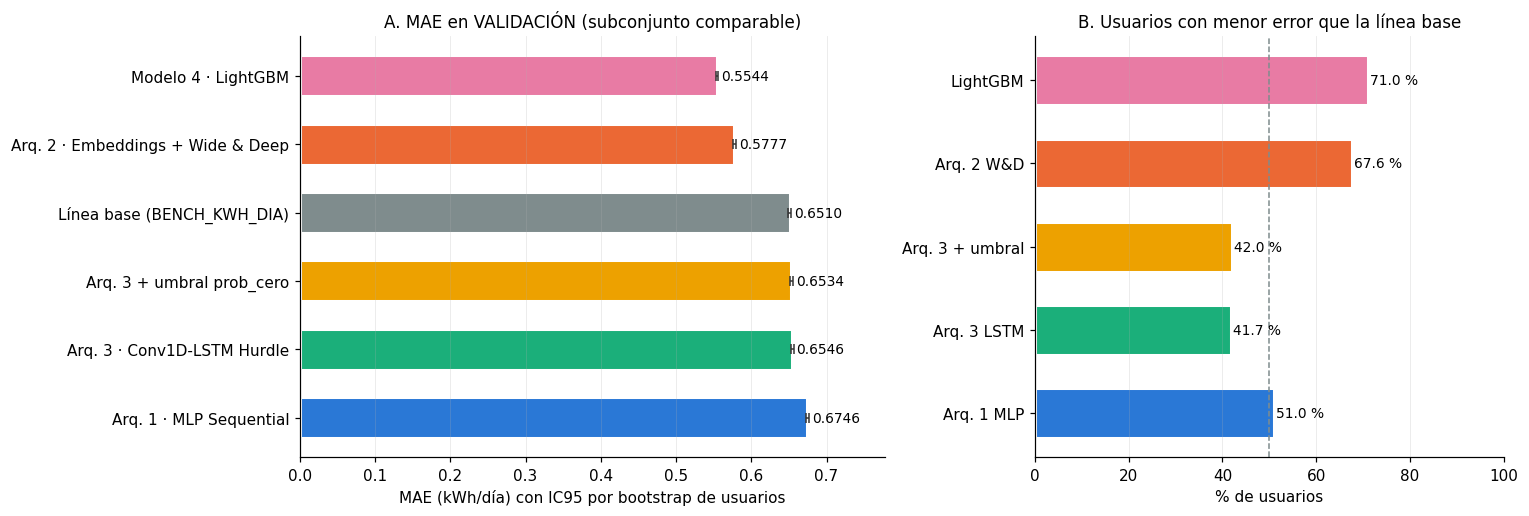

In [21]:
# Figura 1. MAE con IC95 (bootstrap por usuario) y % de usuarios con menor error que la línea base
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.25, 1]})
orden = tabla_boot['MAE por registro'].sort_values().index.tolist()
ax = axes[0]
for i, m in enumerate(orden):
    f = tabla_boot.loc[m]
    ax.barh(i, f['MAE por registro'], height=0.6, color=COLORES[m], edgecolor='white', linewidth=2)
    ax.errorbar(f['MAE por registro'], i,
                xerr=[[f['MAE por registro'] - f['IC95 inf']], [f['IC95 sup'] - f['MAE por registro']]],
                fmt='none', ecolor='#333333', capsize=3, linewidth=1)
    ax.text(f['IC95 sup'] + 0.004, i, f"{f['MAE por registro']:.4f}", va='center', fontsize=9)
ax.set_yticks(np.arange(len(orden)), [ETIQUETAS[m] for m in orden])
ax.invert_yaxis()
ax.set_xlabel('MAE (kWh/día) con IC95 por bootstrap de usuarios')
ax.set_title('A. MAE en VALIDACIÓN (subconjunto comparable)')
ax.set_xlim(0, tabla_boot['IC95 sup'].max() * 1.15)
ax.grid(axis='y', visible=False)

ax = axes[1]
orden_c = [m for m in orden if m != 'LINEA_BASE']
vals = tabla_boot.loc[orden_c, '% usuarios con menor error que la base']
ax.barh(np.arange(len(orden_c)), vals, height=0.6, color=[COLORES[m] for m in orden_c], edgecolor='white', linewidth=2)
for i, v in enumerate(vals):
    ax.text(v + 0.5, i, f'{v:.1f} %', va='center', fontsize=9)
ax.axvline(50, color='#7F8C8D', linestyle='--', linewidth=1)
ax.set_yticks(np.arange(len(orden_c)), [ETIQUETAS_CORTAS[m] for m in orden_c])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('% de usuarios')
ax.set_title('B. Usuarios con menor error que la línea base')
ax.grid(axis='y', visible=False)
plt.tight_layout()
guardar_figura(fig, 'fig01_mae_ic95_validacion')
plt.show()

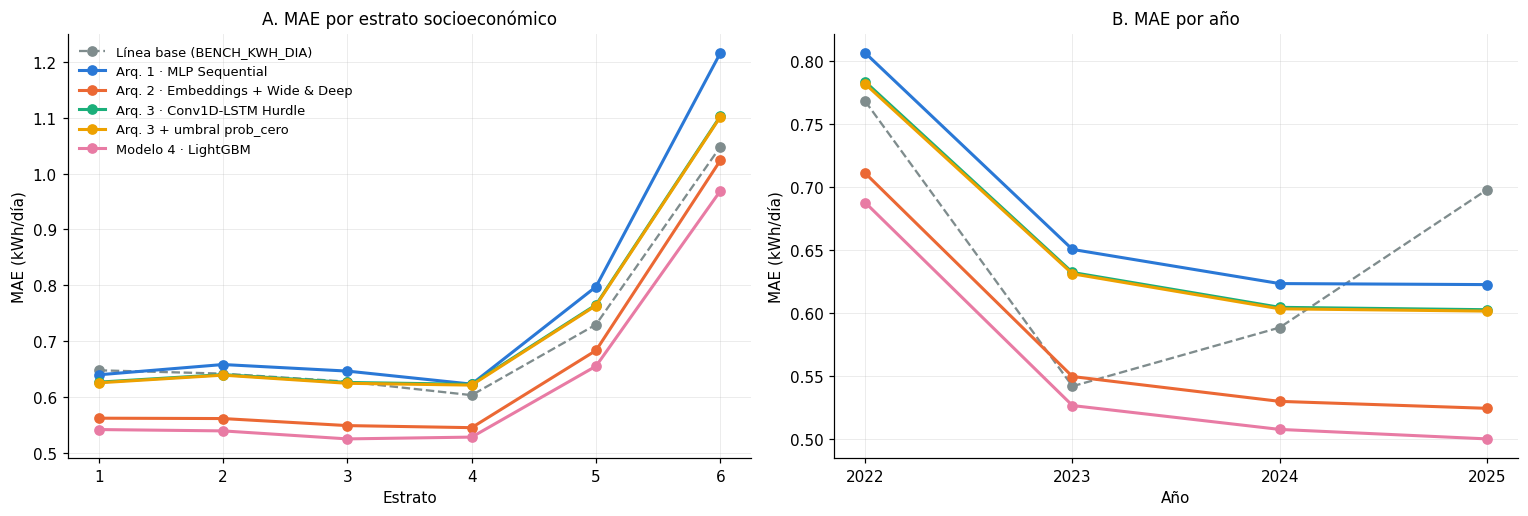

In [22]:
# Figura 2. MAE por estrato y por año (VALIDACIÓN comparable)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, df, g, titulo in [(axes[0], por_estrato, 'Estrato', 'A. MAE por estrato socioeconómico'),
                          (axes[1], por_anio, 'Año', 'B. MAE por año')]:
    piv = df.pivot(index=g, columns='Modelo', values='MAE')
    for m in MODELOS:
        estilo = dict(linestyle='--', linewidth=1.5) if m == 'LINEA_BASE' else dict(linewidth=2)
        ax.plot(piv.index.astype(int), piv[m], marker='o', markersize=6, color=COLORES[m], label=ETIQUETAS[m], **estilo)
    ax.set_xticks(piv.index.astype(int))
    ax.set_xlabel(g)
    ax.set_ylabel('MAE (kWh/día)')
    ax.set_title(titulo)
axes[0].legend(fontsize=8.5, frameon=False, loc='upper left')
plt.tight_layout()
guardar_figura(fig, 'fig02_mae_por_estrato_y_anio')
plt.show()

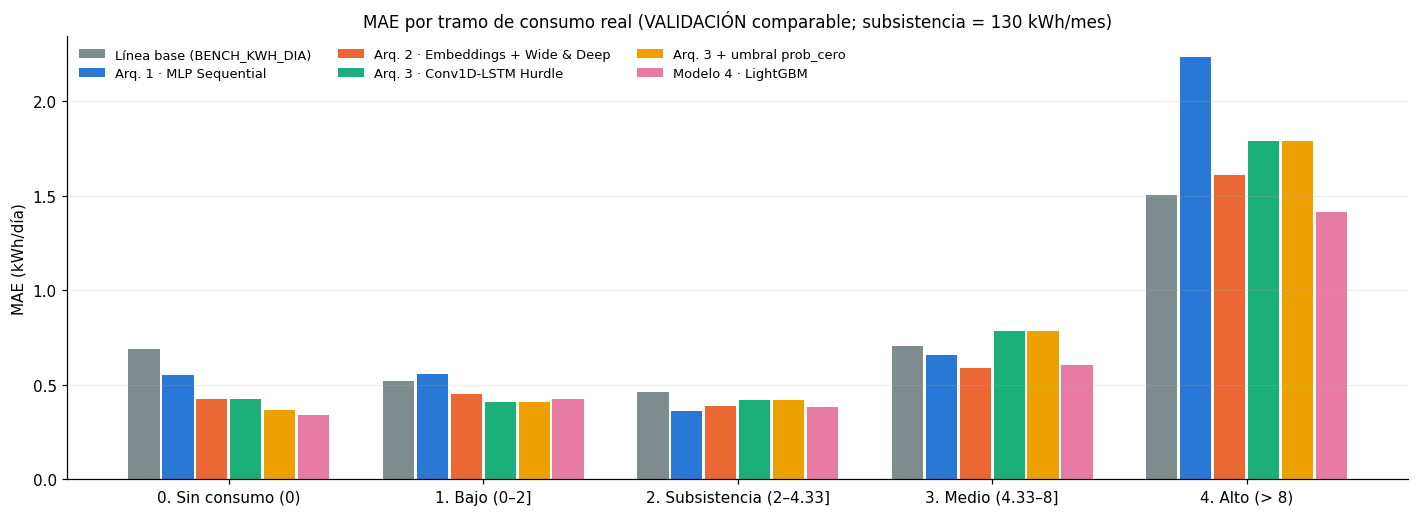

In [23]:
# Figura 3. MAE por tramo de consumo (barras agrupadas)
piv = por_tramo.pivot(index='Tramo de consumo (kWh/día)', columns='Modelo', values='MAE')[MODELOS]
fig, ax = plt.subplots(figsize=(13, 4.8))
ancho = 0.8 / len(MODELOS)
x = np.arange(len(piv))
for k, m in enumerate(MODELOS):
    ax.bar(x + (k - (len(MODELOS) - 1) / 2) * ancho, piv[m], width=ancho * 0.92, color=COLORES[m], label=ETIQUETAS[m])
ax.set_xticks(x, piv.index)
ax.set_ylabel('MAE (kWh/día)')
ax.set_title('MAE por tramo de consumo real (VALIDACIÓN comparable; subsistencia = 130 kWh/mes)')
ax.legend(fontsize=8.5, frameon=False, ncol=3)
ax.grid(axis='x', visible=False)
plt.tight_layout()
guardar_figura(fig, 'fig03_mae_por_tramo_consumo')
plt.show()

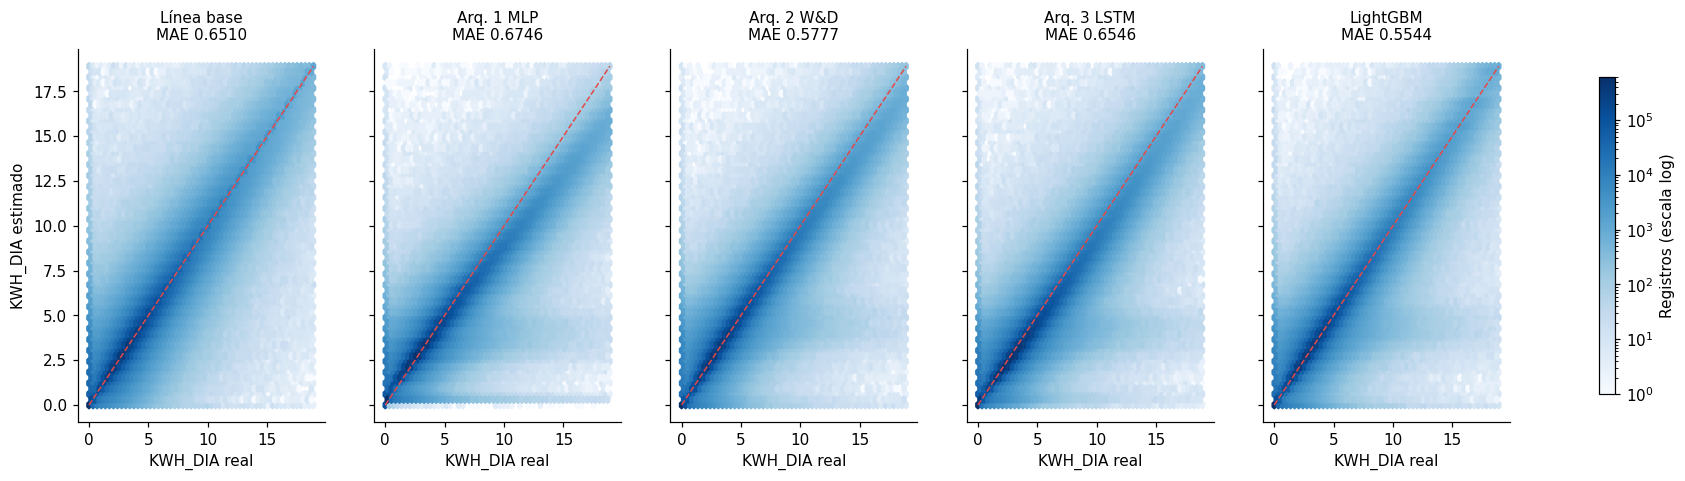

In [24]:
# Figura 4. Real frente a estimado (hexbin, escala log) para la línea base y los cuatro modelos
paneles = [m for m in ['LINEA_BASE', 'arq1_mlp_sequential', 'arq2_embeddings_wide_deep', ARQ3, 'lightgbm'] if m in pred_valid]
lim = float(np.percentile(y_valid[mask_comp], 99))
fig, axes = plt.subplots(1, len(paneles), figsize=(4.2 * len(paneles), 4.4), sharex=True, sharey=True)
for ax, m in zip(axes, paneles):
    mm = mask_comp & np.isfinite(pred_valid[m])
    hb = ax.hexbin(y_valid[mm], pred_valid[m][mm], gridsize=55, extent=(0, lim, 0, lim), bins='log', cmap='Blues', mincnt=1)
    ax.plot([0, lim], [0, lim], color='#e34948', linestyle='--', linewidth=1)
    ax.set_title(f"{ETIQUETAS_CORTAS[m]}\nMAE {tabla_boot.loc[m, 'MAE por registro']:.4f}", fontsize=10)
    ax.set_xlabel('KWH_DIA real')
    ax.grid(False)
axes[0].set_ylabel('KWH_DIA estimado')
fig.colorbar(hb, ax=axes, label='Registros (escala log)', shrink=0.85)
guardar_figura(fig, 'fig04_real_vs_estimado')
plt.show()

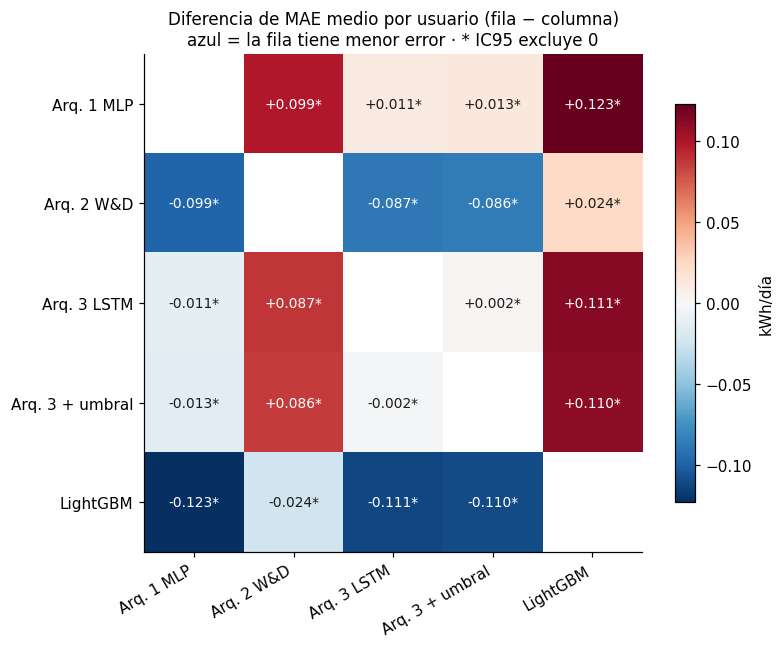

In [25]:
# Figura 5. Matriz de diferencias pareadas de MAE por usuario (fila − columna)
etq = [ETIQUETAS_CORTAS[m] for m in CANDIDATOS]
M = media.to_numpy(dtype='float64')
vmax = np.nanmax(np.abs(M))
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(M, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
for i, a in enumerate(CANDIDATOS):
    for j, b in enumerate(CANDIDATOS):
        if a != b:
            ax.text(j, i, f'{media.loc[a, b]:+.3f}{"*" if significativa.loc[a, b] else ""}',
                    ha='center', va='center', fontsize=9,
                    color='white' if abs(media.loc[a, b]) > 0.6 * vmax else '#1a1a1a')
ax.set_xticks(range(len(etq)), etq, rotation=30, ha='right')
ax.set_yticks(range(len(etq)), etq)
ax.grid(False)
ax.set_title('Diferencia de MAE medio por usuario (fila − columna)\nazul = la fila tiene menor error · * IC95 excluye 0')
fig.colorbar(im, ax=ax, label='kWh/día', shrink=0.8)
plt.tight_layout()
guardar_figura(fig, 'fig05_diferencias_pareadas')
plt.show()

## 10. Exportación

In [26]:
# 10.1 Tabla LaTeX para el capítulo de resultados (VALIDACIÓN, subconjunto comparable)
tabla_tex = (tabla_valid.loc['Comparable con la línea base'].reindex(MODELOS)
             [['n', 'MAE', 'RMSE', 'R2', 'Sesgo', 'Reducción MAE vs. línea base (%)']].copy())
tabla_tex['IC95 MAE'] = [f"[{tabla_boot.loc[m, 'IC95 inf']:.4f}; {tabla_boot.loc[m, 'IC95 sup']:.4f}]" for m in MODELOS]
tabla_tex.index = [ETIQUETAS[m] for m in MODELOS]
tabla_tex = tabla_tex.rename(columns={'R2': 'R$^2$', 'Reducción MAE vs. línea base (%)': 'Red. MAE (\\%)'})
latex = (tabla_tex.style
         .format({'n': '{:,.0f}', 'MAE': '{:.4f}', 'RMSE': '{:.4f}', 'R$^2$': '{:.4f}', 'Sesgo': '{:+.4f}',
                  'Red. MAE (\\%)': '{:+.2f}'}, na_rep='--')
         .to_latex(hrules=True, position='htbp', position_float='centering', label='tab:validacion_4_modelos',
                   caption='Desempeño de los cuatro modelos supervisados y de la línea base semestral en la partición '
                           'de validación (subconjunto comparable). IC95 por \\textit{bootstrap} de usuarios.'))
with open(os.path.join(DIR_RESULTADOS, 'tabla_validacion_4_modelos.tex'), 'w', encoding='utf-8') as fh:
    fh.write(latex)
print(latex)

\begin{table}[htbp]
\centering
\caption{Desempeño de los cuatro modelos supervisados y de la línea base semestral en la partición de validación (subconjunto comparable). IC95 por \textit{bootstrap} de usuarios.}
\label{tab:validacion_4_modelos}
\begin{tabular}{lrrrrrrl}
\toprule
 & n & MAE & RMSE & R$^2$ & Sesgo & Red. MAE (\%) & IC95 MAE \\
\midrule
Línea base (BENCH_KWH_DIA) & 16,048,529 & 0.6510 & 1.3698 & 0.8691 & +0.0115 & +0.00 & [0.6491; 0.6529] \\
Arq. 1 · MLP Sequential & 16,048,529 & 0.6746 & 1.3272 & 0.8771 & -0.1970 & -3.64 & [0.6725; 0.6767] \\
Arq. 2 · Embeddings + Wide & Deep & 16,048,529 & 0.5777 & 1.2035 & 0.8989 & -0.1213 & +11.26 & [0.5760; 0.5793] \\
Arq. 3 · Conv1D-LSTM Hurdle & 16,048,529 & 0.6546 & 1.2899 & 0.8839 & -0.3213 & -0.56 & [0.6529; 0.6562] \\
Arq. 3 + umbral prob_cero & 16,048,529 & 0.6534 & 1.2904 & 0.8838 & -0.3241 & -0.37 & [0.6516; 0.6550] \\
Modelo 4 · LightGBM & 16,048,529 & 0.5544 & 1.1834 & 0.9023 & -0.0327 & +14.83 & [0.5530; 0.5560] \\
\botto

In [27]:
# 10.2 Predicciones de VALIDACIÓN de todos los modelos (para análisis posteriores) y resumen JSON
predicciones = T_valid['meta'].assign(
    KWH_DIA=y_valid, BENCH_KWH_DIA=T_valid['bench'], COMPARABLE=mask_comp.astype('int8'), ESTRATO=T_valid['estrato'],
    **{f'PRED_{m.upper().replace("+", "_")}': pred_valid[m] for m in CANDIDATOS})
if prob_cero_valid.get(ARQ3) is not None:
    predicciones['PROB_CERO_ARQ3'] = prob_cero_valid[ARQ3]
predicciones.to_parquet(os.path.join(DIR_RESULTADOS, 'predicciones_validacion_4_modelos.parquet'), index=False)
del predicciones

comp = tabla_valid.loc['Comparable con la línea base']
mejor_valid = comp.drop(index='LINEA_BASE')['MAE'].idxmin()
resumen = {
    'modelo_seleccionado_prueba': MODELO_SELECCIONADO,
    'criterio_seleccion': 'MAE mínimo en PRUEBA (todos los registros), entre las cuatro familias',
    'menor_mae_validacion_comparable': mejor_valid,
    'umbral_prob_cero_arq3': UMBRAL_CERO,
    'diferencias_protocolo': {'frac_monitor_redes': frac_monitor(prep['particion']['hex_inicio_monitor']),
                              'frac_monitor_lightgbm': frac_monitor(resumen_lgb['particion']['hex_inicio_monitor'])},
    'prueba_todos': tabla_prueba.loc['Todos los registros'][['n', 'MAE', 'RMSE', 'R2', 'Sesgo']].to_dict(orient='index'),
    'validacion_comparable': comp.to_dict(orient='index'),
    'bootstrap_vs_linea_base': tabla_boot.to_dict(orient='index'),
    'comparaciones_pareadas': tabla_pares.to_dict(orient='records'),
}
with open(os.path.join(DIR_RESULTADOS, 'resumen_validacion_4_modelos.json'), 'w', encoding='utf-8') as fh:
    json.dump(resumen, fh, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

print('Archivos en Drive:')
for directorio in (DIR_RESULTADOS, DIR_FIGURAS):
    for archivo in sorted(os.listdir(directorio)):
        print(f' - {os.path.relpath(os.path.join(directorio, archivo), DRIVE_RAIZ)}')

Archivos en Drive:
 - V2/Resultados_7_Validacion/00_protocolo_cuadernos_5_y_6.csv
 - V2/Resultados_7_Validacion/01_comparacion_prueba_4_modelos.csv
 - V2/Resultados_7_Validacion/02_metricas_validacion_4_modelos.csv
 - V2/Resultados_7_Validacion/03_ranking_prueba_vs_validacion.csv
 - V2/Resultados_7_Validacion/04_bootstrap_ic95_vs_linea_base.csv
 - V2/Resultados_7_Validacion/05_bootstrap_comparaciones_pareadas.csv
 - V2/Resultados_7_Validacion/05b_matriz_diferencias_pareadas.csv
 - V2/Resultados_7_Validacion/06_validacion_por_estrato.csv
 - V2/Resultados_7_Validacion/07_validacion_por_anio.csv
 - V2/Resultados_7_Validacion/08_validacion_por_tramo_consumo.csv
 - V2/Resultados_7_Validacion/09_validacion_por_tipo_medidor.csv
 - V2/Resultados_7_Validacion/10_arq3_prob_cero_validacion.csv
 - V2/Resultados_7_Validacion/cache_predicciones
 - V2/Resultados_7_Validacion/predicciones_validacion_4_modelos.parquet
 - V2/Resultados_7_Validacion/resumen_validacion_4_modelos.json
 - V2/Resultados_7_Va

In [28]:
# 10.3 Resumen en texto (insumo para las conclusiones)
sel, base = MODELO_SELECCIONADO, 'LINEA_BASE'
f_sel = tabla_boot.loc[sel]
print(f"1. Selección en PRUEBA: {ETIQUETAS[sel]} (MAE {tabla_prueba.loc[('Todos los registros', sel), 'MAE']:.4f} kWh/día), "
      f"frente a {ETIQUETAS[SEGUNDO_PRUEBA]} ({tabla_prueba.loc[('Todos los registros', SEGUNDO_PRUEBA), 'MAE']:.4f}).")
print(f"2. VALIDACIÓN (comparable): MAE {comp.loc[sel, 'MAE']:.4f} vs. {comp.loc[base, 'MAE']:.4f} de la línea base "
      f"({comp.loc[sel, 'Reducción MAE vs. línea base (%)']:.2f} % menos); RMSE {comp.loc[sel, 'RMSE']:.4f} vs. "
      f"{comp.loc[base, 'RMSE']:.4f}; R² {comp.loc[sel, 'R2']:.4f} vs. {comp.loc[base, 'R2']:.4f}.")
print(f"3. Mejora por usuario frente a la línea base: {f_sel['Mejora por usuario (base − modelo)']:.4f} kWh/día "
      f"IC95 [{f_sel['Mejora IC95 inf']:.4f}; {f_sel['Mejora IC95 sup']:.4f}]; "
      f"{f_sel['% usuarios con menor error que la base']:.1f} % de los usuarios con menor error.")
print('4. Todos los modelos frente a la línea base (comparable):')
for m in CANDIDATOS:
    f = tabla_boot.loc[m]
    print(f"   - {ETIQUETAS[m]:<36} MAE {f['MAE por registro']:.4f} | reducción {comp.loc[m, 'Reducción MAE vs. línea base (%)']:+.2f} % | "
          f"{'supera' if f['Supera a la base (IC95 > 0)'] else 'NO supera'} a la línea base")
mismo_orden = (ranking['Puesto PRUEBA'].dropna() == ranking['Puesto VALIDACIÓN'].dropna()).all()
print(f"5. ¿Se mantiene en VALIDACIÓN el orden de PRUEBA? {'Sí' if mismo_orden else 'No (ver tabla 03)'}.")

1. Selección en PRUEBA: Modelo 4 · LightGBM (MAE 0.5547 kWh/día), frente a Arq. 2 · Embeddings + Wide & Deep (0.5779).
2. VALIDACIÓN (comparable): MAE 0.5544 vs. 0.6510 de la línea base (14.83 % menos); RMSE 1.1834 vs. 1.3698; R² 0.9023 vs. 0.8691.
3. Mejora por usuario frente a la línea base: 0.0991 kWh/día IC95 [0.0963; 0.1019]; 71.0 % de los usuarios con menor error.
4. Todos los modelos frente a la línea base (comparable):
   - Arq. 1 · MLP Sequential              MAE 0.6746 | reducción -3.64 % | NO supera a la línea base
   - Arq. 2 · Embeddings + Wide & Deep    MAE 0.5777 | reducción +11.26 % | supera a la línea base
   - Arq. 3 · Conv1D-LSTM Hurdle          MAE 0.6546 | reducción -0.56 % | NO supera a la línea base
   - Arq. 3 + umbral prob_cero            MAE 0.6534 | reducción -0.37 % | NO supera a la línea base
   - Modelo 4 · LightGBM                  MAE 0.5544 | reducción +14.83 % | supera a la línea base
5. ¿Se mantiene en VALIDACIÓN el orden de PRUEBA? Sí.


## 11. Conclusiones

*(Completar con los valores impresos en 10.3 y las tablas `01` a `10` de `V2/Resultados_7_Validacion`.)*

1. **Selección entre familias (PRUEBA).** Modelo con menor MAE en PRUEBA entre las tres redes y LightGBM, y su ventaja sobre el segundo. En los cuadernos 5 y 6, LightGBM (MAE 0,5547) quedó por delante de la mejor red (Arq. 2, 0,5779); confirmar si el orden se mantiene en VALIDACIÓN (tabla `03`).
2. **Frente a la línea base (VALIDACIÓN).** Reducción de MAE y RMSE de cada modelo en el subconjunto comparable, IC95 por usuario y % de usuarios con menor error (tabla `04`).
3. **Entre modelos.** Diferencias pareadas e IC95 (tabla `05`, figura 5): si la ventaja del modelo seleccionado sobre los demás es significativa y de qué magnitud relativa.
4. **¿Se justifica la complejidad de las redes?** Discutir con Grinsztajn et al. (2022): en datos tabulares mensuales, un modelo de árboles con las mismas variables tabulares iguala o supera a las redes; la Arq. 3, que además usa la secuencia de 12 meses, no aprovecha esa información adicional (la secuencia solo tiene rezagos completos en t−1, t−3 y t−12).
5. **Heterogeneidad.** Estratos 5 y 6 y consumos altos concentran el mayor error; revisar el tramo de subsistencia y los meses con consumo cero, donde la línea base falla más (tablas `06` a `09`).
6. **Limitaciones.** Parada temprana con distinta fracción de monitoreo (5 % redes, 10 % LightGBM); partición por usuario y no temporal; no se evaluaron ensambles para no ajustar nada en el *hold-out*; con ≈ 360 mil usuarios, diferencias pequeñas pueden ser significativas sin ser relevantes en la práctica.

### Referencias

- Efron, B. y Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
- Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS, Datasets and Benchmarks Track*.
- Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *Advances in Neural Information Processing Systems*, 30.